# EDA complémentaire

**Contributeurs :** Cécile · **Date :** 27/10/2026

Analyses réalisées après le premier rapport. Équipements : nouvelle source, la BPE en évolution de l'Insee (nombre d'équipements par bassin de vie en 2015, 2020 et 2025), à la place de la table de présence par commune.

## 0. Chargement

In [21]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display
import re

# config.py se trouve à la racine du projet
racine = Path.cwd()
while not (racine / "config.py").exists() and racine != racine.parent:
    racine = racine.parent
sys.path.insert(0, str(racine))
from config import DATA_RAW, DATA_OUT

pd.set_option("display.max_columns", None)

# BPE en évolution (source bpe_evolution du téléchargement), lue en texte
fichier = DATA_RAW / "DS_BPE_EVOLUTION_2025_data.csv"
separateur = ";" if ";" in fichier.open(encoding="utf-8").readline() else ","   # séparateur lu sur la 1re ligne
bpe_evol = pd.read_csv(fichier, sep=separateur, dtype=str)

## Audit rapide : BPE en évolution (2015, 2020, 2025)

**Contributeurs :** Cécile · **Date :** 25/10/2026

Jeu de données Insee DS_BPE_EVOLUTION (catalogue Melodi) : nombre d'équipements par type, par territoire et par année, sur trois années espacées de 5 ans, comparables dans le temps. On vérifie son contenu, ses mailles géographiques (le bassin de vie est-il disponible ?) et ses années.

In [4]:
# Structure, mailles géographiques, années, types d'équipements
print("Lignes :", len(bpe_evol), "| colonnes :", bpe_evol.shape[1])
display(bpe_evol.head())

# Pour chaque colonne : nombre de valeurs différentes, valeurs manquantes et premiers exemples
for col in bpe_evol.columns:
    valeurs = bpe_evol[col].dropna().unique()
    print(f"{col} : {len(valeurs)} valeurs différentes | manquantes : {bpe_evol[col].isna().sum()} | "
          f"exemples : {list(valeurs[:8])}")

# Mailles géographiques disponibles et nombre de territoires pour chacune
print(bpe_evol.groupby("GEO_OBJECT")["GEO"].nunique().sort_values(ascending=False))

Lignes : 1922859 | colonnes : 9


,GEO,GEO_OBJECT,FACILITY_TYPE,BPE_MEASURE,UNIT_MULT,UNIT_MEASURE,OBS_STATUS,TIME_PERIOD,OBS_VALUE
0,FM,FRANCE,F127,FACILITIES,0,NR,O,2015,NaN
1,FM,FRANCE,D252,FACILITIES,0,NR,O,2015,NaN
2,FM,FRANCE,F130,FACILITIES,0,NR,O,2015,NaN
3,FM,FRANCE,D108,FACILITIES,0,NR,O,2015,NaN
4,F,FRANCE,D253,FACILITIES,0,NR,O,2015,NaN


GEO : 6521 valeurs différentes | manquantes : 0 | exemples : ['FM', 'F', '13056', '14366', '14371', '14431', '13103', '13104']
GEO_OBJECT : 9 valeurs différentes | manquantes : 0 | exemples : ['FRANCE', 'BV2022', 'UU2020', 'AAV2020', 'DEP', 'REG', 'ARR', 'EPCI']
FACILITY_TYPE : 152 valeurs différentes | manquantes : 0 | exemples : ['F127', 'D252', 'F130', 'D108', 'D253', 'A126', 'B307', 'B310']
BPE_MEASURE : 1 valeurs différentes | manquantes : 0 | exemples : ['FACILITIES']
UNIT_MULT : 1 valeurs différentes | manquantes : 0 | exemples : ['0']
UNIT_MEASURE : 1 valeurs différentes | manquantes : 0 | exemples : ['NR']
OBS_STATUS : 2 valeurs différentes | manquantes : 0 | exemples : ['O', 'A']
TIME_PERIOD : 3 valeurs différentes | manquantes : 0 | exemples : ['2015', '2020', '2025']
OBS_VALUE : 4029 valeurs différentes | manquantes : 158836 | exemples : ['17', '5', '22', '13', '4', '2', '11', '1']
GEO_OBJECT
UU2020     2473
BV2022     1707
EPCI       1253
AAV2020     699
ARR         333
ZE

In [5]:
# BPE en évolution au bassin de vie : bassins couverts, valeurs manquantes, types renseignés par année
bv_equip = bpe_evol[bpe_evol["GEO_OBJECT"] == "BV2022"].copy()
bv_equip["OBS_VALUE"] = pd.to_numeric(bv_equip["OBS_VALUE"])
print("Lignes au bassin de vie :", len(bv_equip), "| bassins :", bv_equip["GEO"].nunique())

# Les valeurs manquantes correspondent-elles au statut « O » ?
display(pd.crosstab(bv_equip["OBS_STATUS"], bv_equip["OBS_VALUE"].isna().rename("valeur manquante")))

# Nombre de types d'équipements renseignés chaque année, et sur combien d'années chaque type est renseigné
renseigne = bv_equip.dropna(subset=["OBS_VALUE"])
display(renseigne.groupby("TIME_PERIOD")["FACILITY_TYPE"].nunique().rename("types renseignés"))
print("Nombre de types selon le nombre d'années renseignées :")
display(renseigne.groupby("FACILITY_TYPE")["TIME_PERIOD"].nunique().value_counts().rename("nombre de types"))

# Correspondance avec les bassins de la table de liaison
bassins_liaison = set(pd.read_parquet(DATA_OUT / "liaison_commune_bv2022.parquet")["BV2022"].dropna())
bassins_bpe = set(bv_equip["GEO"])
print("Bassins de la liaison absents de la BPE :", len(bassins_liaison - bassins_bpe),
      "| bassins de la BPE absents de la liaison :", len(bassins_bpe - bassins_liaison))

Lignes au bassin de vie : 480339 | bassins : 1707


valeur manquante,False,True
OBS_STATUS,,
A,442095,0
O,0,38244


TIME_PERIOD
2015    109
2020    151
2025    152
Name: types renseignés, dtype: int64

Nombre de types selon le nombre d'années renseignées :


TIME_PERIOD
3    108
2     44
Name: nombre de types, dtype: int64

Bassins de la liaison absents de la BPE : 0 | bassins de la BPE absents de la liaison : 0


**Lecture de l'audit**

- **Maille** : le fichier contient directement le bassin de vie (zonage BV2022), le même que notre table de liaison : 1 707 bassins, avec une correspondance parfaite dans les deux sens (aucun bassin manquant d'un côté ou de l'autre). Aucun passage par les communes n'est nécessaire.
- **Années** : 2015, 2020 et 2025, au 1er janvier, comparables dans le temps selon l'Insee.
- **Types d'équipements** : 152 au total ; 108 sont renseignés les trois années, 44 seulement deux années (surtout 2020 et 2025 : 109 types en 2015, 151 en 2020, 152 en 2025).
- **Valeurs manquantes** : elles correspondent toutes au statut « O » (valeur non diffusée) et toutes les valeurs présentes au statut « A » (valeur normale). Ce sont des types d'équipements non retenus pour une année donnée, pas des erreurs.
- **Colonnes inutiles** : BPE_MEASURE, UNIT_MULT et UNIT_MEASURE n'ont qu'une seule valeur.

**Impact projet** : cette source donne des comptages officiels d'équipements au bassin de vie, comparables entre 2015, 2020 et 2025, ce que ne garantit pas la comparaison de deux millésimes ordinaires de la BPE. Elle permet aussi de mesurer directement l'hypothèse de stabilité des équipements, en comparant 2015 et 2020 sur les 108 types renseignés les deux années.

In [6]:
# Au bassin de vie : combien de bassins n'ont aucune poste ou aucune boulangerie ?
CODES = {"bureau de poste": "A206", "boulangerie": "B207"}

for nom, code in CODES.items():
    eq = bv_equip[(bv_equip["FACILITY_TYPE"] == code)].dropna(subset=["OBS_VALUE"])
    sans = eq[eq["OBS_VALUE"] == 0].groupby("TIME_PERIOD")["GEO"].nunique()
    total = eq.groupby("TIME_PERIOD")["GEO"].nunique()
    print(f"{nom} ({code}) : bassins sans aucun équipement par année :",
          {annee: f"{sans.get(annee, 0)} sur {total[annee]}" for annee in total.index})

bureau de poste (A206) : bassins sans aucun équipement par année : {'2015': '0 sur 1706', '2020': '6 sur 1706', '2025': '41 sur 1706'}
boulangerie (B207) : bassins sans aucun équipement par année : {'2015': '1 sur 1707', '2020': '0 sur 1707', '2025': '1 sur 1707'}


**Bassins de vie sans bureau de poste ou sans boulangerie**

| Équipement | 2015 | 2020 | 2025 |
|---|---|---|---|
| Bureau de poste (A206) | 0 bassin sur 1 706 | 6 | 41 |
| Boulangerie-pâtisserie (B207) | 1 bassin sur 1 707 | 0 | 1 |

- **À la maille du bassin de vie, la présence ou l'absence de ces équipements ne distingue presque aucun territoire** : en 2020, seuls 6 bassins n'ont pas de bureau de poste et aucun n'est sans boulangerie. Les indicateurs de présence calculés à la commune perdent leur intérêt une fois agrégés au bassin ; il faudrait utiliser le nombre d'équipements, rapporté à la population.
- **Les bureaux de poste ne sont pas stables dans le temps** : le nombre de bassins qui n'en ont plus aucun passe de 0 en 2015 à 41 en 2025. L'hypothèse « les équipements restent en place » ne tient donc pas pour tous les équipements. Hypothèse : une partie de ces bureaux a pu être transformée en agence postale communale ou en relais poste, qui sont des types d'équipements distincts dans la BPE.

### Concordance avec la BPE 2025 communale
Pour de futures sous-unités de bassin (ville-centre, reste du bassin), il faudra des nombres par commune, absents de la BPE en évolution. On vérifie que la BPE 2025 communale (une ligne par équipement) donne les mêmes nombres au bassin de vie.

In [7]:
bpe25 = pd.read_parquet(DATA_RAW / "BPE25.parquet")
print(bpe25.shape)

# Nombre d'équipements par bassin et par type dans BPE25, comparé à la BPE en évolution (2025)
compte_bv = bpe25.groupby(["BV2022", "TYPEQU"]).size().rename("nb_bpe25").reset_index()
evol_2025 = bv_equip[bv_equip["TIME_PERIOD"] == "2025"][["GEO", "FACILITY_TYPE", "OBS_VALUE"]]
compar = evol_2025.merge(compte_bv, left_on=["GEO", "FACILITY_TYPE"],
                         right_on=["BV2022", "TYPEQU"], how="left")
compar["nb_bpe25"] = compar["nb_bpe25"].fillna(0)   # type absent du bassin dans BPE25 = 0 équipement

print("Lignes comparées :", len(compar))
print("Valeurs identiques :", (compar["OBS_VALUE"] == compar["nb_bpe25"]).mean().round(3))

(2921770, 95)
Lignes comparées : 160113
Valeurs identiques : 0.99


### Superficie des bassins de vie

La superficie de chaque commune (en km², géographie 2026) est additionnée par bassin de vie avec la table de liaison. Source : « Liste des communes de France : code INSEE, codes postaux, EPCI, population, superficie » (data.gouv.fr, à partir de données Insee et IGN).

In [8]:
# Superficie des bassins de vie : somme des superficies communales (géographie 2026)
communes = pd.read_csv(DATA_RAW / "communes-france-2026.csv", usecols=["code_insee", "superficie_km2"],
                       dtype={"code_insee": str})
liaison = pd.read_parquet(DATA_OUT / "liaison_commune_bv2022.parquet")

# Une ligne par commune 2026 et son bassin (la liaison contient aussi les anciens codes)
communes_bv = liaison[["CODGEO_2026", "BV2022"]].dropna().drop_duplicates("CODGEO_2026")
communes_bv = communes_bv.merge(communes, left_on="CODGEO_2026", right_on="code_insee", how="left")

print("Communes 2026 :", len(communes_bv),
      "| sans superficie :", communes_bv["superficie_km2"].isna().sum())

superficie_bv = (communes_bv.groupby("BV2022")["superficie_km2"].sum(min_count=1)
                 .rename("superficie_km2").reset_index())
print("Bassins :", len(superficie_bv), "| sans superficie :", superficie_bv["superficie_km2"].isna().sum(),
      "| superficie totale :", round(superficie_bv["superficie_km2"].sum()), "km²")
display(superficie_bv["superficie_km2"].describe().round(1))

Communes 2026 : 34875 | sans superficie : 136
Bassins : 1707 | sans superficie : 26 | superficie totale : 548776 km²


count    1681.0
mean      326.5
std       286.6
min         9.0
25%       132.0
50%       238.0
75%       423.0
max      3066.0
Name: superficie_km2, dtype: float64

In [9]:
# Communes et bassins sans superficie : outre-mer seulement ?
sans = communes_bv[communes_bv["superficie_km2"].isna()]
outre_mer = sans["CODGEO_2026"].str.startswith("97")
print("Communes sans superficie :", len(sans), "| dont outre-mer :", outre_mer.sum())
print("Communes de métropole sans superficie :", sans.loc[~outre_mer, "CODGEO_2026"].tolist())

bassins_sans = superficie_bv.loc[superficie_bv["superficie_km2"].isna(), "BV2022"]
print("Bassins sans superficie hors outre-mer :", bassins_sans[~bassins_sans.str.startswith("97")].tolist())

Communes sans superficie : 136 | dont outre-mer : 129
Communes de métropole sans superficie : ['15031', '15035', '15047', '15141', '60054', '85084', '85165']
Bassins sans superficie hors outre-mer : []


**Lecture**

La superficie est disponible pour les 1 681 bassins de vie de métropole (bassin médian : 238 km², de 9 à 3 066 km² ; total de 548 776 km², proche de la superficie de la France métropolitaine). Les 26 bassins sans superficie sont tous en outre-mer, hors du périmètre de DVF+. En métropole, 7 communes sur environ 34 750 n'ont pas de superficie (4 dans le Cantal, 1 dans l'Oise, 2 en Vendée), probablement des communes fusionnées en 2026 dont le code diffère entre les deux fichiers : la superficie de leurs bassins est légèrement sous-estimée, ce qui est négligeable.

In [10]:
# Population municipale par bassin de vie et par année (somme des communes, source SSMSI / Insee)
delinq_pop = pd.read_parquet(DATA_OUT / "delinquance_commune_annee.parquet",
                             columns=["code_commune", "annee", "insee_pop"])

pop_bv = delinq_pop.merge(liaison[["CODGEO_INI", "BV2022"]], left_on="code_commune",
                          right_on="CODGEO_INI", how="left", validate="many_to_one")
print("Communes sans bassin :", pop_bv.loc[pop_bv["BV2022"].isna(), "code_commune"].nunique())

pop_bv = pop_bv.groupby(["BV2022", "annee"], as_index=False)["insee_pop"].sum()
print(pop_bv.shape, "| bassins :", pop_bv["BV2022"].nunique())
display(pop_bv[pop_bv["annee"].isin([2015, 2020, 2025])].groupby("annee")["insee_pop"].sum())

Communes sans bassin : 0
(17070, 3) | bassins : 1707


annee
2020    67418672
2025    68350798
Name: insee_pop, dtype: int32

**Lecture :** population disponible pour les 1 707 bassins, de 2016 à 2025 (67,4 millions d'habitants en 2020, 68,4 millions en 2025, outre-mer compris). Pas de population pour 2015 : la population à associer à la BPE 2015 reste à choisir.

### Types d'équipements par domaine
La première lettre du code d'équipement donne le domaine de la BPE. On compte, pour chaque domaine, le nombre de types, ceux renseignés les trois années, et le nombre total d'équipements (bassins de métropole).

In [11]:
DOMAINES = {"A": "Services aux particuliers", "B": "Commerces", "C": "Enseignement",
            "D": "Santé et action sociale", "E": "Transports et déplacements",
            "F": "Sports, loisirs et culture", "G": "Tourisme"}

# Bassins de métropole seulement (outre-mer hors périmètre de DVF+)
metro = bv_equip[~bv_equip["GEO"].str.startswith("97")].copy()
metro["domaine"] = metro["FACILITY_TYPE"].str[0].map(DOMAINES)

# Nombre de types par domaine, et types renseignés les trois années
annees_renseignees = metro.dropna(subset=["OBS_VALUE"]).groupby("FACILITY_TYPE")["TIME_PERIOD"].nunique()
types = metro[["FACILITY_TYPE", "domaine"]].drop_duplicates()
types["trois_annees"] = types["FACILITY_TYPE"].map(annees_renseignees) == 3

tableau = types.groupby("domaine").agg(types=("FACILITY_TYPE", "size"),
                                       types_3_annees=("trois_annees", "sum"))

# Nombre total d'équipements par domaine et par année
total = metro.pivot_table(index="domaine", columns="TIME_PERIOD", values="OBS_VALUE", aggfunc="sum")
display(tableau.join(total))

,types,types_3_annees,2015,2020,2025
domaine,,,,,
Commerces,34,34,369405.0,365178.0,360632.0
Enseignement,3,3,1247.0,1206.0,1203.0
Santé et action sociale,56,23,46661.0,347549.0,387697.0
Services aux particuliers,31,29,927490.0,1072436.0,1292456.0
"Sports, loisirs et culture",21,13,89502.0,187783.0,189113.0
Tourisme,4,3,31373.0,41830.0,43153.0
Transports et déplacements,3,3,47723.0,75157.0,97436.0


**Lecture :**
- **Commerces** : les 34 types sont renseignés les trois années ; le nombre d'équipements est stable (369 000 en 2015, 361 000 en 2025).
- **Santé et action sociale** : 33 types sur 56 manquent en 2015. Le total de 2015 (47 000) n'est donc pas comparable à celui de 2020 (348 000) : la hausse vient surtout des types ajoutés, pas d'une vraie évolution.
- **Sports, loisirs et culture** : même problème, 8 types sur 21 manquent en 2015.
- **Services aux particuliers** : 29 types sur 31 renseignés les trois années, et pourtant une forte hausse (+39 % entre 2015 et 2025). Hypothèse : une partie vient de la création de micro-entreprises (artisans, services à domicile), à vérifier type par type.
- **Transports et déplacements** : 3 types seulement, nombre doublé entre 2015 et 2025. Hypothèse : hausse des taxis et VTC, à vérifier.
- **Enseignement** : 3 types seulement, environ 1 200 équipements. L'Insee a exclu les équipements de l'Éducation nationale de ce fichier : le domaine est presque vide.

**Impact projet :** additionner les équipements par domaine mélange des types aux évolutions très différentes, et toute comparaison avec 2015 doit se limiter aux 108 types renseignés les trois années.

# B. Relations entre les domaines d'équipements

### B1. Redondances entre domaines
**Variables :** nombre d'équipements par domaine pour 10 000 habitants, par bassin de vie de métropole, en 2020. L'enseignement est exclu (domaine presque vide : équipements de l'Éducation nationale absents du fichier).

**Pourquoi regarder cela :** des domaines qui portent la même information n'ont pas besoin d'être gardés tous.

**Méthode :** corrélations de Spearman entre les taux des six domaines (distributions asymétriques). Les nombres sont rapportés à la population, sinon ils suivraient tous la taille du bassin.

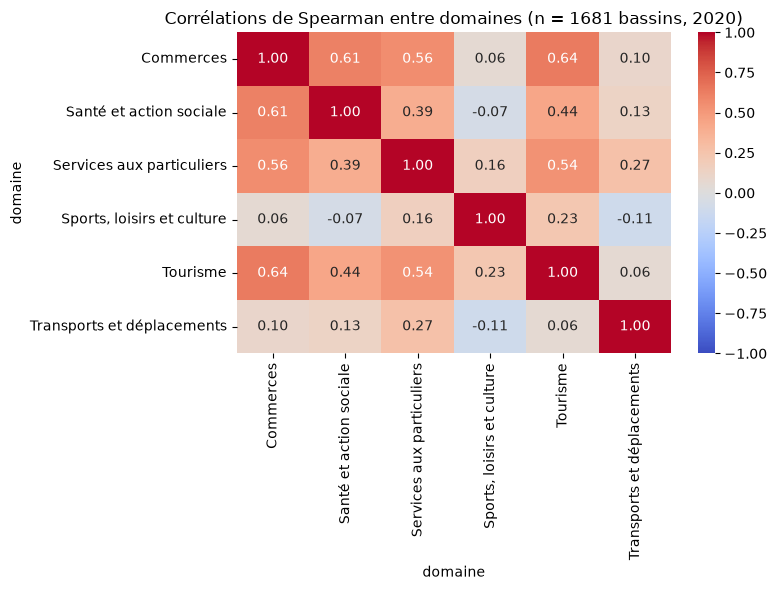

In [12]:
# Nombre d'équipements par domaine, bassins de métropole, 2020, enseignement exclu
eq20 = metro[(metro["TIME_PERIOD"] == "2020") & (metro["domaine"] != "Enseignement")]
dom20 = eq20.pivot_table(index="GEO", columns="domaine", values="OBS_VALUE", aggfunc="sum")

# Taux pour 10 000 habitants (population municipale 2020)
pop20 = pop_bv[pop_bv["annee"] == 2020].set_index("BV2022")["insee_pop"]
taux_dom20 = dom20.div(pop20.reindex(dom20.index), axis=0) * 10000
liste_domaines = list(taux_dom20.columns)

corr = taux_dom20.corr(method="spearman")
plt.figure(figsize=(8, 6))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f")
plt.title(f"Corrélations de Spearman entre domaines (n = {len(taux_dom20)} bassins, 2020)")
plt.tight_layout()
plt.show()

**Constat :** aucun couple de domaines n'est lié à |rho| ≥ 0,8 : les six domaines portent des informations distinctes.
- Quatre domaines forment un groupe lié (rho de 0,39 à 0,64) : commerces, santé et action sociale, services aux particuliers, tourisme. Le lien le plus fort est entre commerces et tourisme (0,64), puis commerces et santé (0,61).
- Sports, loisirs et culture et transports et déplacements sont à part : liens faibles avec tous les autres domaines (rho ≤ 0,27).

**Interprétation :**
- Le groupe commerces, santé, services, tourisme correspond probablement aux bassins qui jouent un rôle de pôle : ils équipent aussi les habitants des bassins voisins et les visiteurs, d'où plus d'équipements par habitant (hypothèse).
- Le lien entre commerces et tourisme vient probablement des zones touristiques, où les commerces servent aussi une population de passage que la population municipale ne compte pas (hypothèse).

**Biais / limites :** les taux sont rapportés à la population municipale, qui ne compte pas les touristes ni les résidents secondaires : dans les bassins touristiques, le nombre d'équipements par habitant est surestimé.

### B2. Répartition sur le territoire
**Pourquoi regarder cela :** un domaine présent dans les mêmes proportions partout ne peut pas expliquer des différences de prix entre bassins de vie.

**Méthode :** pour chaque domaine, taux pour 10 000 habitants en 2020 par bassin de vie de métropole. On regarde l'écart entre les bassins les moins et les plus équipés (D9 / D1), puis la part de ces écarts liée au département (test de Kruskal-Wallis et taille d'effet η²).

In [13]:
def eta2_kruskal(groupes):
    """Kruskal-Wallis + taille d'effet eta² (part de la variabilité des rangs expliquée par les groupes)."""
    H, p = stats.kruskal(*groupes)
    k, n = len(groupes), sum(len(g) for g in groupes)
    return H, p, (H - k + 1) / (n - k)

b2 = taux_dom20.copy()
b2["dep"] = b2.index.str[:2]   # département du bassin (celui de sa commune pôle)

lignes = []
for d in liste_domaines:
    x = b2[d].dropna()
    d1, med, d9 = x.quantile([0.1, 0.5, 0.9])
    groupes = [g[d].dropna().values for _, g in b2.groupby("dep")]
    H, p, eta2 = eta2_kruskal(groupes)
    lignes.append({"domaine": d, "D1": round(d1, 1), "médiane": round(med, 1), "D9": round(d9, 1),
                   "D9 / D1": round(d9 / d1, 1) if d1 > 0 else np.nan,
                   "p-value": f"{p:.1e}", "η² département": round(eta2, 3)})

display(pd.DataFrame(lignes).set_index("domaine").sort_values("η² département", ascending=False))

,D1,médiane,D9,D9 / D1,p-value,η² département
domaine,,,,,,
Services aux particuliers,124.0,166.4,242.0,2.0,2.0e-154,0.578
"Sports, loisirs et culture",24.3,40.4,63.2,2.6,6.9e-96,0.388
Transports et déplacements,1.6,4.2,9.6,6.2,1.1e-90,0.376
Tourisme,1.6,5.0,19.0,12.0,6.1e-69,0.301
Commerces,28.7,47.0,78.5,2.7,1.6e-55,0.250
Santé et action sociale,27.6,42.3,64.9,2.4,1.8e-52,0.239


**Comment lire le tableau (exemple des commerces) :**
- **D1 = 28,7** : 10 % des bassins ont moins de 28,7 commerces pour 10 000 habitants. Ce sont les bassins les moins équipés.
- **Médiane = 47,0** : la moitié des bassins a moins de 47 commerces pour 10 000 habitants, l'autre moitié plus.
- **D9 = 78,5** : 10 % des bassins ont plus de 78,5 commerces pour 10 000 habitants. Ce sont les bassins les plus équipés.
- **D9 / D1 = 2,7** : les bassins les plus équipés ont 2,7 fois plus de commerces par habitant que les moins équipés. S'il valait 1, tous les bassins seraient équipés de la même façon.
- **η² département = 0,25** : 25 % des écarts entre bassins s'expliquent par le département où ils se trouvent ; les 75 % restants viennent de différences entre bassins d'un même département. Repères : 0,01 faible, 0,06 moyen, 0,14 fort.
- **p-value** : avec environ 1 680 bassins, elle est toujours très faible. C'est le η² qu'on interprète.

**Constat :**
- **Aucun domaine n'est homogène sur le territoire** : le rapport D9 / D1 va de 2,0 à 12,0, et le η² dépasse 0,14 pour les six domaines (effet fort du département).
- **Le tourisme** est le domaine le plus inégal entre bassins (D9 / D1 = 12) : les équipements touristiques se concentrent dans quelques bassins.
- **Les transports et déplacements** ont aussi de forts écarts (D9 / D1 = 6,2), mais avec peu d'équipements (médiane de 4,2 pour 10 000 habitants) : dans un petit bassin, quelques équipements suffisent à faire varier le taux.
- **Les services aux particuliers** ont les écarts les plus faibles (D9 / D1 = 2,0) mais le lien le plus fort avec le département (η² = 0,58) : les différences entre bassins sont faibles, mais organisées régionalement.
- **Les commerces et la santé** sont les moins liés au département (η² de 0,24 à 0,25) : leurs différences se jouent davantage entre bassins d'un même département.

**Interprétation :**
- Tous les domaines distinguent les bassins : ils peuvent servir de variables de territoire.
- Le lien fort des services avec le département peut venir de pratiques régionales différentes, par exemple dans l'installation des artisans et des micro-entreprises, qui font partie de ce domaine (hypothèse).

**Biais / limites :** taux rapportés à la population municipale de 2020 ; dans les bassins touristiques, ils sont surestimés (la population de passage n'est pas comptée).

### B3. Évolution dans le temps
**Pourquoi regarder cela :** si les équipements d'un bassin évoluent comme ceux de la France, une valeur fixe suffit. Si certains bassins s'écartent nettement de la tendance nationale (fermetures, départs, baisse des commerces), une valeur par année devient utile.

**Méthode :** types d'équipements renseignés les trois années seulement (comparaison possible avec 2015) ; enseignement exclu. Taux pour 10 000 habitants ; la population de 2016 est utilisée pour 2015 (pas de population 2015 disponible).
1. **Tendance nationale :** somme des équipements des bassins de métropole divisée par la somme des habitants, en 2015, 2020 et 2025.
2. **Écart de chaque bassin à cette tendance :** évolution du taux du bassin moins l'évolution nationale, en points de %, pour 2015 → 2020 et 2020 → 2025.

In [14]:
# 1. Équipements par bassin, année et domaine : types renseignés les trois années, enseignement exclu
types_3 = annees_renseignees[annees_renseignees == 3].index
e3 = metro[metro["FACILITY_TYPE"].isin(types_3) & (metro["domaine"] != "Enseignement")]
nb = e3.pivot_table(index=["GEO", "TIME_PERIOD"], columns="domaine",
                    values="OBS_VALUE", aggfunc="sum").reset_index()

# 2. Population de l'année (2016 pour la BPE 2015)
nb["annee_pop"] = nb["TIME_PERIOD"].astype(int).replace(2015, 2016)
nb = nb.merge(pop_bv, left_on=["GEO", "annee_pop"], right_on=["BV2022", "annee"], how="left")

# 3. Tendance nationale : somme des équipements / somme des habitants
national = nb.groupby("TIME_PERIOD")[liste_domaines + ["insee_pop"]].sum()
taux_nat = national[liste_domaines].div(national["insee_pop"], axis=0) * 10000
print("Taux national pour 10 000 habitants :")
display(taux_nat.round(1))

# 4. Taux de chaque bassin, puis écart de son évolution à l'évolution nationale (points de %)
taux_b = nb.set_index(["GEO", "TIME_PERIOD"])[liste_domaines].div(
    nb.set_index(["GEO", "TIME_PERIOD"])["insee_pop"], axis=0) * 10000
taux_b = taux_b.unstack("TIME_PERIOD")

lignes = []
for d in liste_domaines:
    for debut, fin in [("2015", "2020"), ("2020", "2025")]:
        evol_bv = (taux_b[(d, fin)] / taux_b[(d, debut)] - 1) * 100
        evol_bv = evol_bv.replace([np.inf, -np.inf], np.nan)   # aucun équipement au départ
        evol_nat = (taux_nat.at[fin, d] / taux_nat.at[debut, d] - 1) * 100
        ecart = (evol_bv - evol_nat).dropna()
        lignes.append({"domaine": d, "période": f"{debut} → {fin}",
                       "évolution France (%)": round(evol_nat, 1),
                       "écart D1": round(ecart.quantile(0.1), 1),
                       "écart médian": round(ecart.median(), 1),
                       "écart D9": round(ecart.quantile(0.9), 1),
                       "bassins à plus de 10 points (%)": round((ecart.abs() > 10).mean() * 100, 1)})

display(pd.DataFrame(lignes).set_index(["domaine", "période"]))

Taux national pour 10 000 habitants :


,Commerces,Santé et action sociale,Services aux particuliers,"Sports, loisirs et culture",Tourisme,Transports et déplacements
TIME_PERIOD,,,,,,
2015,57.3,7.2,143.9,13.9,4.9,7.4
2020,55.9,7.4,160.9,14.2,5.1,11.5
2025,54.5,7.7,191.8,13.9,5.3,14.7


évolution France (%)  écart D1  \
domaine                    période                                       
Commerces                  2015 → 2020                  -2.4     -13.8   
                           2020 → 2025                  -2.6      -9.5   
Santé et action sociale    2015 → 2020                   2.2     -16.6   
                           2020 → 2025                   4.8     -19.9   
Services aux particuliers  2015 → 2020                  11.8     -12.9   
                           2020 → 2025                  19.2     -11.7   
Sports, loisirs et culture 2015 → 2020                   2.1      -8.6   
                           2020 → 2025                  -1.7      -7.3   
Tourisme                   2015 → 2020                   5.6     -43.1   
                           2020 → 2025                   3.4     -44.0   
Transports et déplacements 2015 → 2020                  55.6     -88.4   
                           2020 → 2025                  27.9     -58.8   

                                        écart médian  écart D9  \
domaine                    période                               
Commerces                  2015 → 2020          -2.2      12.5   
                           2020 → 2025           1.2      16.5   
Santé et action sociale    2015 → 2020          -0.1      27.4   
                           2020 → 2025          -2.3      22.1   
Services aux particuliers  2015 → 2020          -3.2       7.3   
                           2020 → 2025          -1.2       9.5   
Sports, loisirs et culture 2015 → 2020          -0.1      10.5   
                           2020 → 2025           0.4       7.0   
Tourisme                   2015 → 2020          -6.0      39.7   
                           2020 → 2025          -3.9      45.8   
Transports et déplacements 2015 → 2020         -49.0      25.2   
                           2020 → 2025         -12.4      56.7   

                                        bassins à plus de 10 points (%)  
domaine                    période                                       
Commerces                  2015 → 2020                             31.1  
                           2020 → 2025                             28.2  
Santé et action sociale    2015 → 2020                             45.8  
                           2020 → 2025                             43.6  
Services aux particuliers  2015 → 2020                             25.4  
                           2020 → 2025                             22.5  
Sports, loisirs et culture 2015 → 2020                             18.6  
                           2020 → 2025                             11.4  
Tourisme                   2015 → 2020                             65.3  
                           2020 → 2025                             62.3  
Transports et déplacements 2015 → 2020                             92.7  
                           2020 → 2025                             82.9

**Comment lire le second tableau (exemple : commerces, 2015 → 2020) :**
- **Évolution France = −2,4 %** : le nombre de commerces pour 10 000 habitants a baissé de 2,4 % en France entre 2015 et 2020.
- **Écart D1 = −13,8** : 10 % des bassins ont évolué au moins 13,8 points plus mal que la France (une baisse d'au moins 16 % au lieu de 2,4 %).
- **Écart D9 = 12,5** : 10 % des bassins ont évolué au moins 12,5 points mieux que la France.
- **Bassins à plus de 10 points = 31 %** : près d'un bassin sur trois s'est écarté de plus de 10 points de la tendance nationale, dans un sens ou dans l'autre.

**Constat :**
- **Les bassins divergent en cinq ans, plus ou moins selon le domaine.** Part des bassins qui s'écartent de plus de 10 points de la tendance nationale :
  - sports, loisirs et culture : 11 à 19 % ; services aux particuliers : 23 à 25 % ; commerces : 28 à 31 % ;
  - santé et action sociale : 44 à 46 % ; tourisme : 62 à 65 % ; transports et déplacements : 83 à 93 %.
- **Les deux périodes donnent des résultats proches** : les divergences ne sont pas propres à une période (le covid n'apparaît pas comme une rupture).
- **Transports et déplacements** : la hausse nationale (+56 % puis +28 %) est portée par quelques bassins. L'écart médian est de −49 points entre 2015 et 2020 : la moitié des bassins a progressé d'au moins 49 points de moins que la France.
- **Services aux particuliers** : forte hausse nationale (+12 % puis +19 %), suivie par la plupart des bassins (écart médian de −3 à −1 point).

**Interprétation :**
- Une partie des bassins connaît des évolutions propres, en particulier pour les commerces et la santé : l'hypothèse d'une valeur fixe par bassin ne tient pas pour tous les domaines.
- Une autre partie de ces écarts vient probablement du faible nombre d'équipements dans les petits bassins : quand un bassin compte peu d'équipements, l'ouverture ou la fermeture d'un seul fait varier son taux de plus de 10 points. C'est sans doute le cas des transports (médiane de 4,2 équipements pour 10 000 habitants), du tourisme et de la santé limitée aux types renseignés les trois années.
- La hausse des transports peut venir du développement des taxis et VTC dans les grandes villes (hypothèse, à vérifier type par type).

**Biais / limites :** types renseignés les trois années seulement (23 types de santé sur 56) ; population de 2016 utilisée pour 2015 ; seuil de 10 points arbitraire, plus facilement dépassé par les petits bassins.

**Graphique :** écart de chaque bassin à la tendance nationale entre 2015 et 2020, selon la taille du bassin (seuil : 20 000 habitants en 2020). Si les petits bassins ont des écarts bien plus dispersés que les grands, une partie des divergences vient du faible nombre d'équipements, pas d'une vraie évolution.

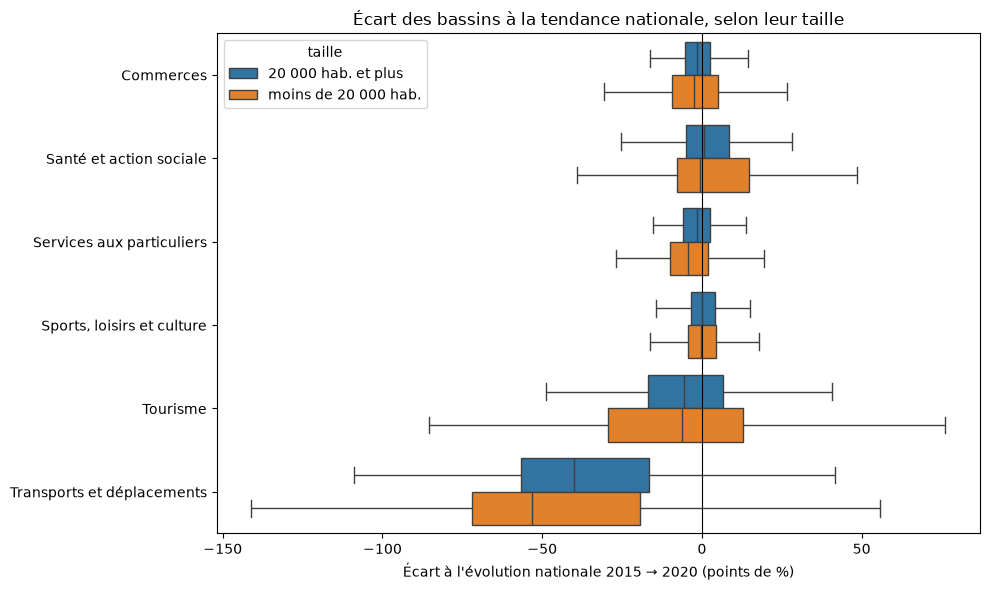

Bassins de 20 000 habitants et plus : 614 sur 1681


In [15]:
# Taille des bassins : population 2020
pop_ref = nb[nb["TIME_PERIOD"] == "2020"].set_index("GEO")["insee_pop"]
grand = (pop_ref >= 20000)

morceaux = []
for d in liste_domaines:
    evol_bv = (taux_b[(d, "2020")] / taux_b[(d, "2015")] - 1) * 100
    evol_bv = evol_bv.replace([np.inf, -np.inf], np.nan)
    evol_nat = (taux_nat.at["2020", d] / taux_nat.at["2015", d] - 1) * 100
    ecart = (evol_bv - evol_nat).dropna()
    taille = np.where(grand.reindex(ecart.index).fillna(False), "20 000 hab. et plus", "moins de 20 000 hab.")
    morceaux.append(pd.DataFrame({"domaine": d, "écart": ecart.values, "taille": taille}))
ecarts = pd.concat(morceaux)

plt.figure(figsize=(10, 6))
sns.boxplot(data=ecarts, x="écart", y="domaine", hue="taille", showfliers=False)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Écart à l'évolution nationale 2015 → 2020 (points de %)")
plt.ylabel("")
plt.title("Écart des bassins à la tendance nationale, selon leur taille")
plt.tight_layout()
plt.show()
print("Bassins de 20 000 habitants et plus :", grand.sum(), "sur", len(grand))

- **Taille des groupes :** 614 bassins de 20 000 habitants et plus, 1 067 de moins de 20 000 habitants (1 681 bassins de métropole).

### B4. Stabilité des bassins dans le temps
**Pourquoi regarder cela :** si un bassin bien équipé le reste, les équipements décrivent surtout **où** l'on est, et une valeur fixe suffit. Si les bassins changent de rang, une valeur par année apporte de l'information.

**Méthode :**
1. **Nuage de points** du taux de chaque bassin en 2015 (abscisse) et en 2020 (ordonnée), en échelles logarithmiques, avec la diagonale « même taux ».
2. **Les bassins gardent-ils leur rang ?** Corrélation de Spearman entre les taux de 2015 et 2020, puis de 2020 et 2025.
3. **D'où viennent les écarts ?** Part des écarts entre toutes les valeurs (bassin × année) qui vient des différences entre bassins, plutôt que de l'évolution dans le temps.

Les calculs sont faits sur tous les bassins, puis sur les bassins de 20 000 habitants et plus.

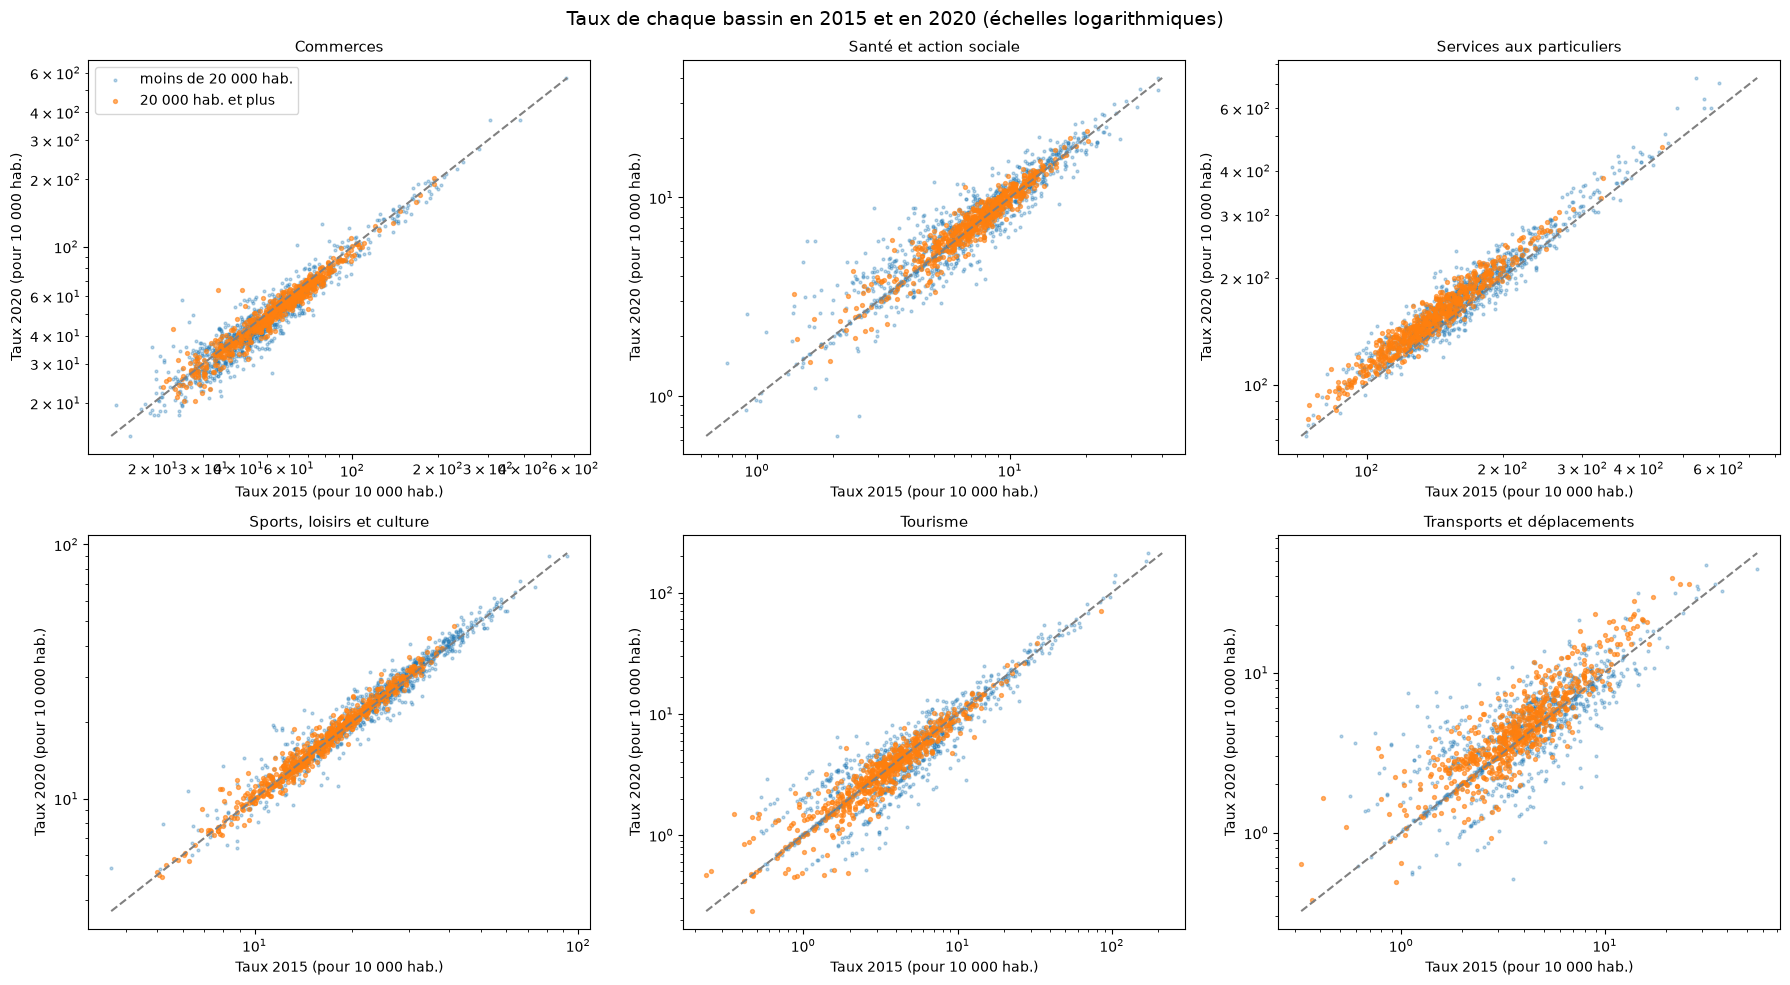

,rho 15/20,rho 20/25,part entre bassins (%),rho 15/20 (grands),rho 20/25 (grands),"part entre bassins (grands, %)"
domaine,,,,,,
Commerces,0.95,0.96,98.5,0.97,0.98,98.2
Santé et action sociale,0.94,0.94,95.7,0.95,0.95,95.9
Services aux particuliers,0.95,0.96,89.7,0.96,0.97,80.4
"Sports, loisirs et culture",0.98,0.99,98.7,0.98,0.99,98.8
Tourisme,0.91,0.90,98.5,0.95,0.94,98.0
Transports et déplacements,0.82,0.83,85.6,0.87,0.88,83.0


In [16]:
# 1. Nuages de points 2015 / 2020, couleur selon la taille du bassin
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, d in zip(axes.flatten(), liste_domaines):
    t = taux_b[d][["2015", "2020"]].dropna()
    t = t[(t["2015"] > 0) & (t["2020"] > 0)]          # échelle logarithmique : pas de taux nul
    g = grand.reindex(t.index).fillna(False)
    ax.scatter(t.loc[~g, "2015"], t.loc[~g, "2020"], s=4, alpha=0.3, label="moins de 20 000 hab.")
    ax.scatter(t.loc[g, "2015"], t.loc[g, "2020"], s=8, alpha=0.6, label="20 000 hab. et plus")
    lim = [t.min().min(), t.max().max()]
    ax.plot(lim, lim, color="grey", linestyle="--")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(d, fontsize=11)
    ax.set_xlabel("Taux 2015 (pour 10 000 hab.)")
    ax.set_ylabel("Taux 2020 (pour 10 000 hab.)")
axes[0, 0].legend()
fig.suptitle("Taux de chaque bassin en 2015 et en 2020 (échelles logarithmiques)", fontsize=14)
plt.tight_layout()
plt.show()

# 2 et 3. Rangs et part des écarts entre bassins, tous les bassins puis grands bassins
def stabilite(t):
    rho_1 = stats.spearmanr(t["2015"], t["2020"], nan_policy="omit")[0]
    rho_2 = stats.spearmanr(t["2020"], t["2025"], nan_policy="omit")[0]
    t = t.dropna()
    part = t.mean(axis=1).var() / t.stack().var() * 100
    return round(rho_1, 2), round(rho_2, 2), round(part, 1)

lignes = []
for d in liste_domaines:
    t = taux_b[d]
    r1, r2, p = stabilite(t)
    r1g, r2g, pg = stabilite(t[grand.reindex(t.index).fillna(False)])
    lignes.append({"domaine": d, "rho 15/20": r1, "rho 20/25": r2, "part entre bassins (%)": p,
                   "rho 15/20 (grands)": r1g, "rho 20/25 (grands)": r2g, "part entre bassins (grands, %)": pg})

display(pd.DataFrame(lignes).set_index("domaine"))

**Comment lire le tableau (exemple : commerces, tous les bassins) :**
- **rho 15/20 = 0,95** : les bassins ont presque le même classement en 2015 et en 2020. Un bassin parmi les plus équipés en 2015 l'est encore en 2020.
- **part entre bassins = 98,5 %** : 98,5 % des écarts entre toutes les valeurs (bassin × année) viennent des différences entre bassins ; 1,5 % seulement vient de l'évolution dans le temps.
- **Colonnes « grands »** : même calcul limité aux bassins de 20 000 habitants et plus.

**Constat :**
- **Graphiques :** pour les commerces, les sports et les services, les points forment une bande étroite le long de la diagonale : chaque bassin garde presque le même taux. Le nuage est plus dispersé pour la santé et le tourisme, et surtout pour les transports, où la plupart des points sont au-dessus de la diagonale (hausse générale).
- **Tableau :**

| Profil | Domaines | rho | Part des écarts entre bassins |
|---|---|---|---|
| Caractéristique très stable du bassin | Commerces, sports, loisirs et culture, tourisme, santé | 0,90 à 0,99 | 96 à 99 % |
| Stable, avec une forte tendance nationale | Services aux particuliers | 0,95 à 0,97 | 90 % (80 % pour les grands bassins) |
| Moins stable | Transports et déplacements | 0,82 à 0,88 | 83 à 86 % |

- Les résultats sont proches pour les grands bassins : la stabilité n'est pas un effet du bruit des petits bassins.

**Interprétation :**
- Les équipements décrivent surtout **où** l'on est : les écarts entre bassins sont beaucoup plus grands que leurs évolutions en cinq ans. Les divergences vues en B3 sont réelles pour certains bassins, mais restent petites par rapport aux différences entre bassins.
- Les services aux particuliers et les transports sont les domaines où l'évolution dans le temps pèse le plus, du fait de leur forte hausse nationale.

**Biais / limites :** types renseignés les trois années seulement ; population de 2016 utilisée pour 2015.

**Comment lire le tableau (exemple : commerces, tous les bassins) :**
- **rho 15/20 = 0,95** : les bassins ont presque le même classement en 2015 et en 2020. Un bassin parmi les plus équipés en 2015 l'est encore en 2020.
- **part entre bassins = 98,5 %** : 98,5 % des écarts entre toutes les valeurs (bassin × année) viennent des différences entre bassins ; 1,5 % seulement vient de l'évolution dans le temps.
- **Colonnes « grands »** : même calcul limité aux bassins de 20 000 habitants et plus.

**Constat :**
- **Graphiques :** pour les commerces, les sports et les services, les points forment une bande étroite le long de la diagonale : chaque bassin garde presque le même taux. Le nuage est plus dispersé pour la santé et le tourisme, et surtout pour les transports, où la plupart des points sont au-dessus de la diagonale (hausse générale).
- **Tableau :**

| Profil | Domaines | rho | Part des écarts entre bassins |
|---|---|---|---|
| Caractéristique très stable du bassin | Commerces, sports, loisirs et culture, tourisme, santé | 0,90 à 0,99 | 96 à 99 % |
| Stable, avec une forte tendance nationale | Services aux particuliers | 0,95 à 0,97 | 90 % (80 % pour les grands bassins) |
| Moins stable | Transports et déplacements | 0,82 à 0,88 | 83 à 86 % |

- Les résultats sont proches pour les grands bassins : la stabilité n'est pas un effet du bruit des petits bassins.

**Interprétation :**
- Les équipements décrivent surtout **où** l'on est : les écarts entre bassins sont beaucoup plus grands que leurs évolutions en cinq ans. Les divergences vues en B3 sont réelles pour certains bassins, mais restent petites par rapport aux différences entre bassins.
- Les services aux particuliers et les transports sont les domaines où l'évolution dans le temps pèse le plus, du fait de leur forte hausse nationale.

**Biais / limites :** types renseignés les trois années seulement ; population de 2016 utilisée pour 2015.

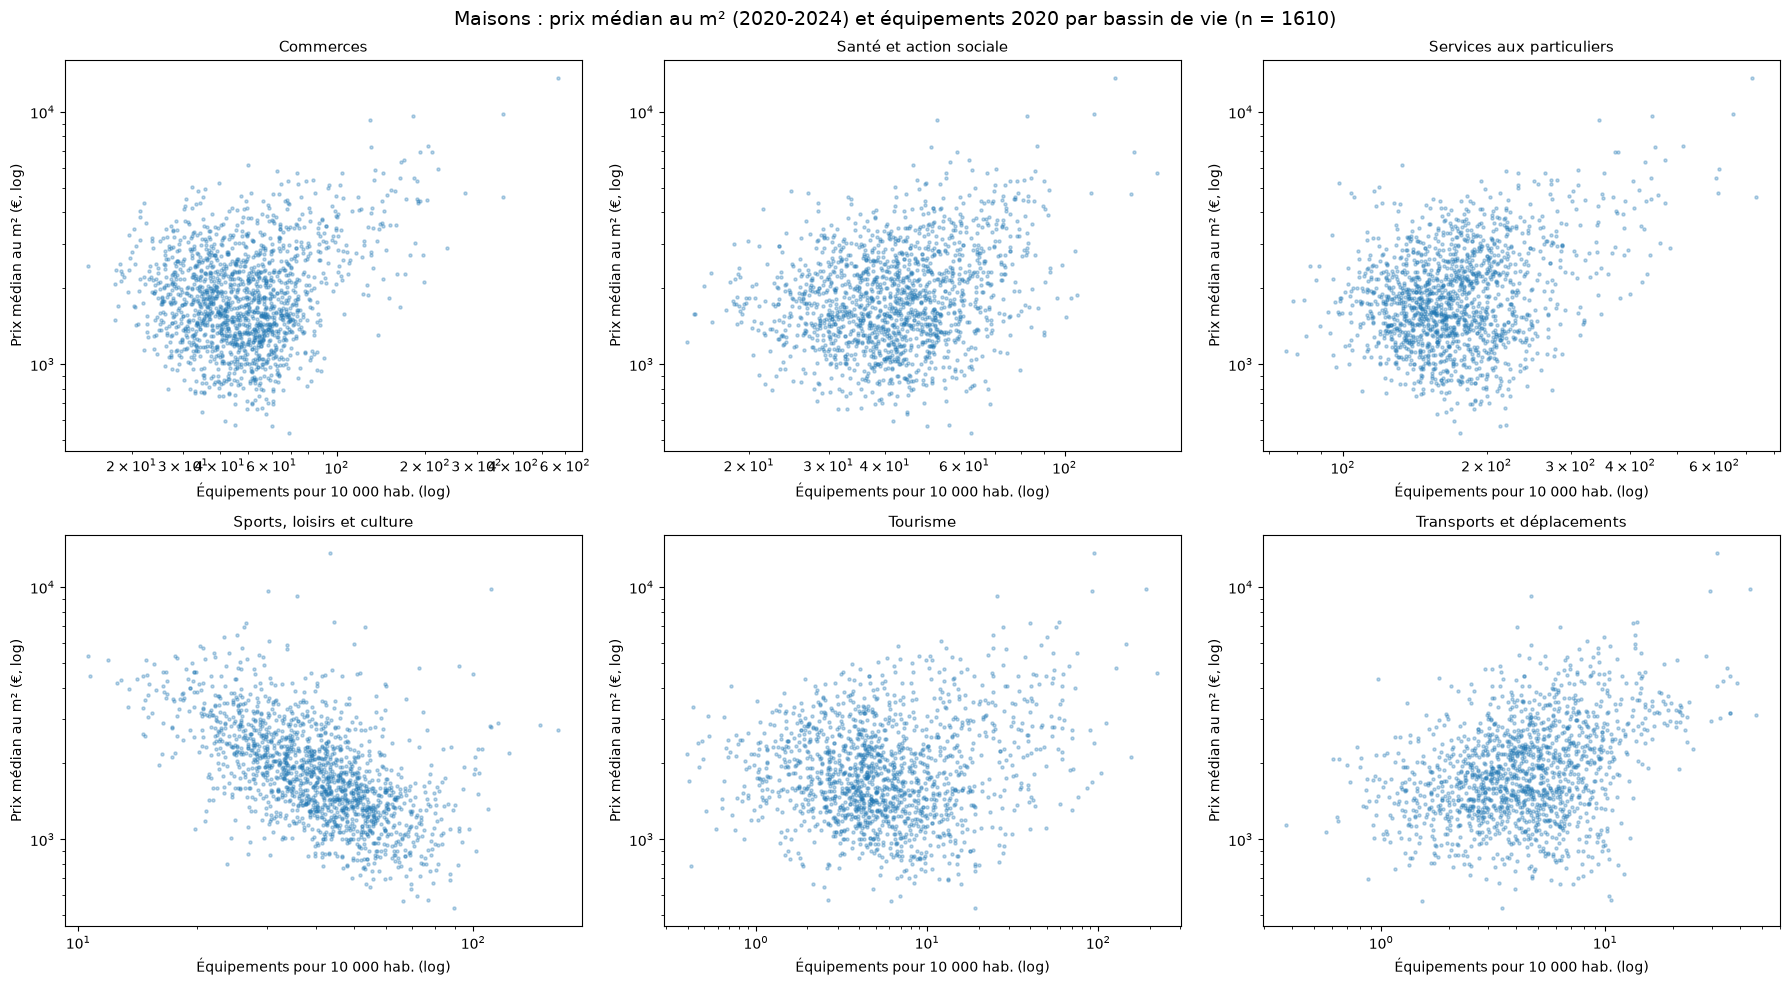

,rho maisons,p-value maisons,rho appartements,p-value appartements
domaine,,,,
"Sports, loisirs et culture",-0.60,7.1e-155,-0.51,6.8e-73
Tourisme,0.03,2.2e-01,0.12,7.7e-05
Commerces,0.11,1.6e-05,0.11,3.0e-04
Services aux particuliers,0.20,1.8e-15,0.20,2.4e-11
Santé et action sociale,0.22,1.9e-19,0.19,2.2e-10
Transports et déplacements,0.35,8.4e-47,0.33,5.1e-30


Bassins : maisons 1610 | appartements 1099


In [17]:
# 1. Ventes 2020-2024 : mêmes règles d'exclusion que la table cible (bloc 4)
ventes = pd.read_parquet(DATA_OUT / "dvf_plus_residentiel.parquet",
                         columns=["anneemut", "l_codinsee", "libtypbien", "valeurfonc", "sbati"])
ventes = ventes[ventes["anneemut"].between(2020, 2024)]
ventes["prix_m2"] = ventes["valeurfonc"] / ventes["sbati"]
ventes = ventes[ventes["valeurfonc"].notna() & (ventes["valeurfonc"] > 0)
                & ventes["prix_m2"].between(50, 50000)].copy()
ventes["type_bien"] = ventes["libtypbien"].map({"UNE MAISON": "maison", "UN APPARTEMENT": "appart"})

# 2. Rattachement au bassin de vie, prix médian par bassin et type de bien (au moins 30 ventes)
ventes = ventes.merge(liaison[["CODGEO_INI", "BV2022"]], left_on="l_codinsee",
                      right_on="CODGEO_INI", how="left", validate="many_to_one")
prix = ventes.groupby(["BV2022", "type_bien"])["prix_m2"].agg(n="count", prix="median").reset_index()
prix = prix[prix["n"] >= 30]

# 3. Rapprochement avec les taux d'équipement 2020
c1 = prix.merge(taux_dom20, left_on="BV2022", right_index=True, how="inner")

# 4. Nuages de points : maisons
m = c1[c1["type_bien"] == "maison"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, d in zip(axes.flatten(), liste_domaines):
    ax.scatter(m[d], m["prix"], s=5, alpha=0.3)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(d, fontsize=11)
    ax.set_xlabel("Équipements pour 10 000 hab. (log)")
    ax.set_ylabel("Prix médian au m² (€, log)")
fig.suptitle(f"Maisons : prix médian au m² (2020-2024) et équipements 2020 par bassin de vie (n = {len(m)})", fontsize=14)
plt.tight_layout()
plt.show()

# 5. Corrélations de Spearman, maisons et appartements
lignes = []
for d in liste_domaines:
    ligne = {"domaine": d}
    for t, nom in [("maison", "maisons"), ("appart", "appartements")]:
        x = c1[c1["type_bien"] == t]
        rho, p = stats.spearmanr(x[d], x["prix"], nan_policy="omit")
        ligne[f"rho {nom}"] = round(rho, 2)
        ligne[f"p-value {nom}"] = f"{p:.1e}"
    lignes.append(ligne)
display(pd.DataFrame(lignes).set_index("domaine").sort_values("rho maisons"))
print("Bassins : maisons", (c1["type_bien"] == "maison").sum(), "| appartements", (c1["type_bien"] == "appart").sum())

**Comment lire le tableau (exemple : transports et déplacements, maisons, rho = 0,35) :**
- **Ce que mesure rho :** on classe les bassins selon leur nombre d'équipements de transport pour 10 000 habitants, puis selon leur prix au m², et on compare les deux classements.
- **Le signe :** positif, les bassins plus équipés ont plutôt des prix plus élevés ; négatif, plutôt des prix plus bas.
- **La valeur :** repères 0,1 lien faible, 0,3 moyen, 0,5 fort. Avec 0,35, le lien est moyen ; rho² ≈ 0,12 : environ 12 % des écarts de classement sont liés au taux d'équipement.
- **La p-value :** avec plus de 1 000 bassins, elle est très faible même pour un lien faible. Au-dessus de 0,05 (tourisme, maisons : p = 0,22), on ne peut pas conclure à un lien. C'est rho qu'on interprète.

**Constat :**
- **Sports, loisirs et culture : lien négatif fort** (−0,60 pour les maisons, −0,51 pour les appartements). Les bassins qui ont le plus d'équipements par habitant sont les moins chers.
- **Transports et déplacements : lien positif moyen** (0,35 et 0,33).
- **Santé et services aux particuliers : liens positifs faibles** (de 0,19 à 0,22).
- **Commerces : lien très faible** (0,11) ; **tourisme : pas de lien** pour les maisons (0,03, non significatif), lien très faible pour les appartements (0,12).
- Les nuages de points sont très dispersés : à taux d'équipement égal, les prix varient fortement d'un bassin à l'autre. Pour les commerces, le prix ne monte qu'à partir des taux les plus élevés : le lien n'est pas régulier.

**Interprétation :**
- Un taux par habitant mesure aussi la densité : un bassin rural possède un minimum d'équipements (stade, salle, terrain) pour peu d'habitants, ce qui lui donne un taux élevé, alors que ses prix sont bas. Le lien négatif des sports reflète probablement l'opposition entre rural et urbain plus que l'effet des équipements (hypothèse).
- À l'inverse, les transports (gares, taxis) se concentrent dans les zones urbaines, plus chères : leur lien positif reflète probablement aussi l'effet « ville ».

**Biais / limites :** associations, pas causes ; population municipale (touristes et résidents secondaires non comptés) ; prix médian sur 2020-2024 et équipements de 2020.

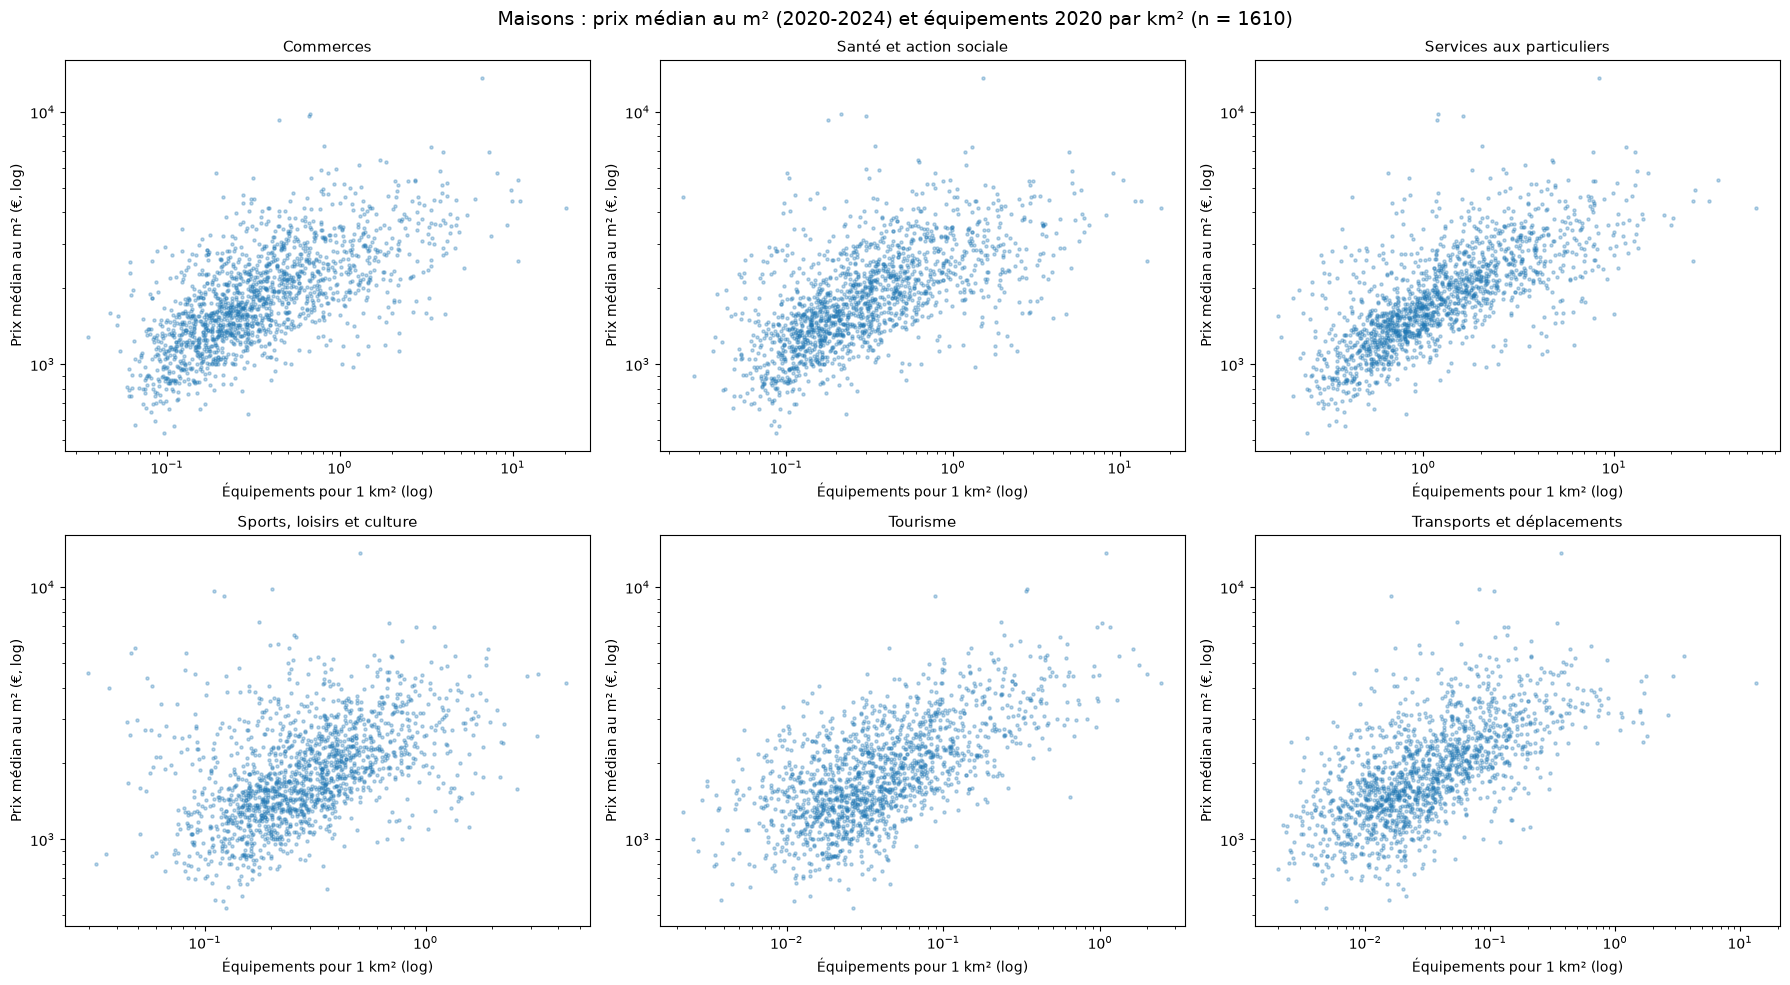

,rho maisons,rho appartements,rho avec la densité
variable,,,
"Sports, loisirs et culture",0.52,0.37,0.93
Tourisme,0.59,0.55,0.51
Densité de population,0.63,0.48,1.00
Santé et action sociale,0.66,0.50,0.94
Transports et déplacements,0.66,0.55,0.81
Commerces,0.68,0.53,0.90
Services aux particuliers,0.75,0.59,0.96


In [18]:
# Équipements pour 1 km² et densité de population (2020)
sup = superficie_bv.set_index("BV2022")["superficie_km2"].reindex(dom20.index)
dens_dom20 = dom20.div(sup, axis=0)
dens_dom20["Densité de population"] = pop20.reindex(dom20.index) / sup

c1b = prix.merge(dens_dom20, left_on="BV2022", right_index=True, how="inner")

# Nuages de points : maisons, équipements par km²
m = c1b[c1b["type_bien"] == "maison"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, d in zip(axes.flatten(), liste_domaines):
    ax.scatter(m[d], m["prix"], s=5, alpha=0.3)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(d, fontsize=11)
    ax.set_xlabel("Équipements pour 1 km² (log)")
    ax.set_ylabel("Prix médian au m² (€, log)")
fig.suptitle(f"Maisons : prix médian au m² (2020-2024) et équipements 2020 par km² (n = {len(m)})", fontsize=14)
plt.tight_layout()
plt.show()

# Corrélations avec le prix, et avec la densité de population
lignes = []
for d in liste_domaines + ["Densité de population"]:
    ligne = {"variable": d}
    for t, nom in [("maison", "maisons"), ("appart", "appartements")]:
        x = c1b[c1b["type_bien"] == t]
        ligne[f"rho {nom}"] = round(stats.spearmanr(x[d], x["prix"], nan_policy="omit")[0], 2)
    ligne["rho avec la densité"] = round(stats.spearmanr(dens_dom20[d], dens_dom20["Densité de population"],
                                                         nan_policy="omit")[0], 2)
    lignes.append(ligne)
display(pd.DataFrame(lignes).set_index("variable").sort_values("rho maisons"))

**Constat :**
- **Rapportés à la superficie, tous les domaines vont avec des prix plus élevés** : rho de 0,52 (sports) à 0,75 (services aux particuliers) pour les maisons, de 0,37 à 0,59 pour les appartements. Le lien négatif des sports en C1 (−0,60) devient positif (0,52).
- **La densité de population seule** est liée au prix à 0,63 (maisons) et 0,48 (appartements).
- **Les équipements par km² suivent presque exactement la densité de population** : rho de 0,90 à 0,96 pour les commerces, la santé, les services et les sports ; 0,81 pour les transports.
- **Le tourisme est l'exception** : peu lié à la densité (0,51) mais lié au prix (0,59 et 0,55). Il porte une information propre.

**Interprétation :**
- Le nombre d'équipements par km² mesure surtout la densité : les zones denses ont à la fois plus d'équipements et des prix plus élevés (effet « ville »).
- Le nombre d'équipements par km² est égal au taux par habitant multiplié par la densité. Avec la densité dans le modèle, l'information supplémentaire des équipements est portée par le taux par habitant : c'est lui qu'il faut garder, à côté de la densité.
- Le tourisme reflète probablement l'attractivité des zones littorales et de montagne, qui ne dépend pas de la densité (hypothèse).

**Biais / limites :** superficie totale du bassin (forêts, terres agricoles et montagnes comprises), qui sous-estime la densité réelle des zones habitées.

### C1 ter. Lien avec le prix à densité égale
**Pourquoi regarder cela :** en C1, le taux d'équipement par habitant mélange l'offre d'équipements et le caractère rural ou urbain du bassin. On cherche si le taux par habitant reste lié au prix une fois l'effet de la densité de population retiré.

**Méthode :** corrélation de Spearman partielle. Les bassins sont classés selon le taux, le prix et la densité ; on retire du classement du taux, puis de celui du prix, la part expliquée par la densité (régression linéaire sur les rangs) ; on corrèle ce qui reste.

In [19]:
def spearman_partiel(x, y, z):
    """Corrélation de Spearman entre x et y, à z égal (effet de z retiré des rangs de x et de y)."""
    d = pd.DataFrame({"x": x, "y": y, "z": z}).dropna().rank()
    res_x = d["x"] - np.polyval(np.polyfit(d["z"], d["x"], 1), d["z"])
    res_y = d["y"] - np.polyval(np.polyfit(d["z"], d["y"], 1), d["z"])
    return np.corrcoef(res_x, res_y)[0, 1]

# Taux par habitant (C1) + densité de population
c1t = c1.merge(dens_dom20[["Densité de population"]], left_on="BV2022", right_index=True, how="left")

lignes = []
for d in liste_domaines:
    ligne = {"domaine": d}
    for t, nom in [("maison", "maisons"), ("appart", "appartements")]:
        x = c1t[c1t["type_bien"] == t]
        ligne[f"rho {nom} (C1)"] = round(stats.spearmanr(x[d], x["prix"], nan_policy="omit")[0], 2)
        ligne[f"rho partiel {nom}"] = round(spearman_partiel(x[d], x["prix"], x["Densité de population"]), 2)
    lignes.append(ligne)

display(pd.DataFrame(lignes).set_index("domaine").sort_values("rho partiel maisons"))

,rho maisons (C1),rho partiel maisons,rho appartements (C1),rho partiel appartements
domaine,,,,
"Sports, loisirs et culture",-0.60,-0.26,-0.51,-0.27
Commerces,0.11,0.27,0.11,0.24
Santé et action sociale,0.22,0.27,0.19,0.22
Tourisme,0.03,0.37,0.12,0.39
Transports et déplacements,0.35,0.37,0.33,0.33
Services aux particuliers,0.20,0.57,0.20,0.45


**Comment lire le tableau (exemple : tourisme, maisons) :** en C1, le taux d'équipements touristiques par habitant n'était pas lié au prix (rho = 0,03). À densité de population égale, le lien devient moyen (rho partiel = 0,37) : parmi des bassins de même densité, ceux qui ont plus d'équipements touristiques par habitant ont des prix plus élevés. En C1, l'effet de la densité masquait ce lien.

**Constat :**
- **Tous les domaines restent liés au prix à densité égale** (|rho partiel| de 0,22 à 0,57) : le taux par habitant apporte une information en plus de la densité.
- **Services aux particuliers : le lien le plus fort** (0,57 pour les maisons, 0,45 pour les appartements, contre 0,20 en C1).
- **Tourisme et transports : liens moyens** (de 0,33 à 0,39). Pour le tourisme, le lien était caché en C1.
- **Commerces et santé : liens faibles à moyens** (de 0,22 à 0,27).
- **Sports, loisirs et culture : le lien reste négatif mais diminue de moitié** (de −0,60 à −0,26 pour les maisons) : la plus grande partie du lien de C1 venait du caractère rural des bassins.

**Interprétation :**
- En C1, la densité masquait ou exagérait les liens : un bassin rural a beaucoup d'équipements par habitant et des prix bas. Une fois cet effet retiré, être mieux équipé va avec des prix plus élevés, sauf pour les sports.
- Le lien encore négatif des sports peut venir de bassins qui ont perdu des habitants mais gardé leurs équipements : leur taux par habitant augmente alors que la demande de logements baisse (hypothèse, à vérifier).
- Le lien fort des services peut refléter le niveau de vie des habitants, qui fait vivre les services marchands (hypothèse) : il reste une association, pas une cause.

**Biais / limites :** seule la densité est contrôlée. D'autres caractéristiques du territoire (revenus, littoral, montagne) peuvent expliquer une partie des liens restants. Le retrait de l'effet de la densité suppose un lien régulier entre les rangs (régression linéaire).

# Synthèse

| Constat majeur | Preuve | Conséquence projet | Action |
|---|---|---|---|
| Le fichier BPE en évolution donne des nombres d'équipements comparables en 2015, 2020 et 2025, directement au bassin de vie | Audit : 1 707 bassins, correspondance parfaite avec la table de liaison ; 152 types, dont 108 renseignés les trois années | Pas d'agrégation de communes nécessaire ; pas de nombre par commune | Source retenue au bassin de vie. Pour d'éventuelles sous-unités (ville-centre), complément possible par la BPE 2025 communale (concordance de 99 % au bassin) |
| L'enseignement est presque vide | 3 types, environ 1 200 équipements : équipements de l'Éducation nationale exclus par l'Insee | Ne décrit pas l'offre scolaire réelle | Domaine exclu |
| Les six domaines portent des informations distinctes | B1 : rho entre domaines ≤ 0,64 | Pas de redondance | Les six domaines gardés |
| Aucun domaine n'est homogène sur le territoire | B2 : D9 / D1 de 2,0 à 12,0 ; η² département de 0,24 à 0,58 | Les équipements distinguent les bassins | Variables de territoire |
| Certains bassins divergent de la tendance nationale, mais ces écarts restent petits face aux différences entre bassins | B3 : 11 à 93 % des bassins à plus de 10 points selon le domaine, en partie du bruit des petits bassins. B4 : rho de 0,82 à 0,99 ; 83 à 99 % des écarts viennent des différences entre bassins | Les équipements décrivent surtout « où », peu « quand » | BPE 2020 fixe pour toutes les années (apprentissage, validation, test) ; pas d'interpolation avec 2025 (information publiée après la date de prédiction) |
| Le taux par habitant mesure aussi le caractère rural des bassins | C1 : sports −0,60 avec le prix des maisons | Lien trompeur sans la densité | Garder la densité de population à côté des taux |
| Le nombre d'équipements par km² suit presque exactement la densité | C1 bis : rho de 0,81 à 0,96 avec la densité, sauf tourisme (0,51) | Information déjà portée par la densité | Pas de variable par km² : densité + taux par habitant |
| À densité égale, tous les domaines restent liés au prix | C1 ter : rho partiels de 0,22 (santé) à 0,57 (services) ; sports −0,26 | Le taux par habitant apporte une information propre | Les six domaines gardés, sports compris |

## Variables candidates pour la modélisation

| Variable | Construite à partir de | Maille | Justification |
|---|---|---|---|
| Densité de population | population municipale / superficie | bassin de vie | C1 bis : rho = 0,63 (maisons) et 0,48 (appartements) ; nécessaire pour lire les taux par habitant |
| Commerces pour 10 000 habitants | BPE 2020, domaine B | bassin de vie | C1 ter : rho partiel 0,27 et 0,24 |
| Santé et action sociale pour 10 000 habitants | BPE 2020, domaine D | bassin de vie | C1 ter : 0,27 et 0,22 |
| Services aux particuliers pour 10 000 habitants | BPE 2020, domaine A | bassin de vie | C1 ter : 0,57 et 0,45, le lien le plus fort |
| Sports, loisirs et culture pour 10 000 habitants | BPE 2020, domaine F | bassin de vie | C1 ter : −0,26 et −0,27 |
| Tourisme pour 10 000 habitants | BPE 2020, domaine G | bassin de vie | C1 ter : 0,37 et 0,39 ; peu lié à la densité (0,51) |
| Transports et déplacements pour 10 000 habitants | BPE 2020, domaine E | bassin de vie | C1 ter : 0,37 et 0,33 |

## Prérequis à l'intégration
- **Clé :** code du bassin de vie (`BV2022`), identique à la table de liaison.
- **Population :** population municipale 2020 (`insee_pop`, fichier de délinquance), additionnée par bassin.
- **Superficie :** somme des superficies communales par bassin (fichier des communes 2026).
- **Source :** fichier BPE en évolution disponible sur le Drive partagé et dans le catalogue de téléchargement (`bpe_evolution`), comme le fichier des communes (`communes`).
- **Limites à rappeler dans le rapport :** associations et non causes ; seule la densité est contrôlée (revenus, littoral, montagne non contrôlés) ; population municipale (touristes non comptés) ; superficie totale du bassin, forêts et terres agricoles comprises.

# Logement : audit des millésimes du recensement (2016 à 2023)

**Contributeurs :** Cécile · **Date :** 27/10/2026

La préparation (bloc 7) n'utilise que le recensement 2022. On vérifie si les millésimes 2016 à 2021 ont les mêmes variables, pour pouvoir comparer les bassins dans le temps, puis ce que contient le millésime 2023, publié dans un nouveau format.

Source : Insee, bases infracommunales (IRIS) « Logement », un fichier par millésime, chacun dans la géographie de son année de publication. Fichiers dans `data/raw/logement_millesimes/`.

### Millésimes 2016 à 2022 : mêmes variables ?

In [26]:
dossier_log = DATA_RAW / "logement_millesimes"

def lire_logement(an):
    """Base IRIS Logement d'un millésime, codes en texte, année retirée des noms (P17_LOG -> P_LOG)."""
    if an == 2016:
        df = pd.read_excel(dossier_log / "base-ic-logement-2016" / "base-ic-logement-2016.xls",
                           sheet_name=0, header=5, dtype={"IRIS": str, "COM": str})
    else:
        df = pd.read_csv(dossier_log / f"base-ic-logement-{an}_csv" / f"base-ic-logement-{an}.CSV",
                         sep=";", dtype={"IRIS": str, "COM": str}, low_memory=False)
    df.columns = [re.sub(r"^([CP])\d{2}_", r"\1_", c) for c in df.columns]
    return df

logements = {an: lire_logement(an) for an in range(2016, 2023)}

# Effectifs utilisés par la préparation (bloc 7), sans l'année dans le nom
EFFECTIFS_LOG = ["P_LOG", "P_RP", "P_MEN", "P_LOGVAC", "P_RSECOCC", "P_MAISON", "P_APPART",
                 "P_RP_M30M2", "P_RP_3040M2", "P_RP_100120M2", "P_RP_120M2P", "P_NBPI_RP",
                 "P_RP_ACH1919", "P_RP_ACH1945", "P_RP_ACH2019", "P_RP_PROP", "P_RP_LOC", "P_RP_LOCHLMV",
                 "P_MEN_ANEM0002", "P_ANEM_RP", "P_NPER_RP", "P_RP_VOIT1P", "P_RP_VOIT2P", "P_RP_GARL",
                 "C_RP_SUROCC_MOD", "C_RP_SUROCC_ACC"]

# Structure de chaque millésime et effectifs du bloc 7 absents
lignes = []
for an, df in logements.items():
    absents = [c for c in EFFECTIFS_LOG if c not in df.columns]
    lignes.append({"millésime": an, "IRIS": len(df), "communes": df["COM"].nunique(),
                   "colonnes": df.shape[1], "effectifs du bloc 7 absents": ", ".join(absents) or "aucun"})
display(pd.DataFrame(lignes).set_index("millésime"))

# Liste complète des effectifs absents, et colonnes « période de construction » et « suroccupation » de chaque millésime
for an, df in logements.items():
    absents = [c for c in EFFECTIFS_LOG if c not in df.columns]
    proches = [c for c in df.columns if "ACH" in c or "SUROCC" in c]
    print(f"{an} | absents : {absents}\n       colonnes ACH / SUROCC : {proches}")

,IRIS,communes,colonnes,effectifs du bloc 7 absents
millésime,,,,
2016,49637,35382,102,"P_RP_ACH1919, P_RP_ACH1945, P_RP_ACH2019, C_RP..."
2017,49280,34995,97,"P_RP_ACH1919, P_RP_ACH1945, P_RP_ACH2019, C_RP..."
2018,49285,34993,97,"P_RP_ACH1919, P_RP_ACH1945, P_RP_ACH2019, C_RP..."
2019,49282,34990,97,"P_RP_ACH1919, P_RP_ACH1945, P_RP_ACH2019, C_RP..."
2020,49273,34980,96,"P_RP_ACH1919, P_RP_ACH1945, P_RP_ACH2019, C_RP..."
2021,49280,34970,96,"P_RP_ACH1919, P_RP_ACH1945, P_RP_ACH2019, C_RP..."
2022,49276,34960,101,aucun


2016 | absents : ['P_RP_ACH1919', 'P_RP_ACH1945', 'P_RP_ACH2019', 'C_RP_SUROCC_MOD', 'C_RP_SUROCC_ACC']
       colonnes ACH / SUROCC : ['P_RP_ACHTOT', 'P_RP_ACH19', 'P_RP_ACH45', 'P_RP_ACH70', 'P_RP_ACH90', 'P_RP_ACH05', 'P_RP_ACH13', 'P_RPMAISON_ACHTOT', 'P_RPMAISON_ACH19', 'P_RPMAISON_ACH45', 'P_RPMAISON_ACH70', 'P_RPMAISON_ACH90', 'P_RPMAISON_ACH05', 'P_RPMAISON_ACH13', 'P_RPAPPART_ACHTOT', 'P_RPAPPART_ACH19', 'P_RPAPPART_ACH45', 'P_RPAPPART_ACH70', 'P_RPAPPART_ACH90', 'P_RPAPPART_ACH05', 'P_RPAPPART_ACH13']
2017 | absents : ['P_RP_ACH1919', 'P_RP_ACH1945', 'P_RP_ACH2019', 'C_RP_SUROCC_MOD', 'C_RP_SUROCC_ACC']
       colonnes ACH / SUROCC : ['P_RP_ACHTOT', 'P_RP_ACH19', 'P_RP_ACH45', 'P_RP_ACH70', 'P_RP_ACH90', 'P_RP_ACH05', 'P_RP_ACH14', 'P_RPMAISON_ACHTOT', 'P_RPMAISON_ACH19', 'P_RPMAISON_ACH45', 'P_RPMAISON_ACH70', 'P_RPMAISON_ACH90', 'P_RPMAISON_ACH05', 'P_RPMAISON_ACH14', 'P_RPAPPART_ACHTOT', 'P_RPAPPART_ACH19', 'P_RPAPPART_ACH45', 'P_RPAPPART_ACH70', 'P_RPAPPART_ACH90', 'P_RPA

**Lecture**

- **Les millésimes 2016 à 2021 ont la même structure que 2022** : environ 49 300 IRIS, de 96 à 102 colonnes. Le nombre de communes baisse de 35 382 (2016) à 34 960 (2022) : ce sont les fusions de communes, que la table de liaison rattache à leur bassin.
- **21 des 26 effectifs utilisés par la préparation existent tels quels tous les ans.**
- **Période de construction : les tranches changent de nom.** Avant 2022, `ACH19` et `ACH45` correspondent à `ACH1919` et `ACH1945` : la part des logements construits avant 1946 est comparable.
- **La dernière tranche n'est pas comparable** : « de 2006 à N-3 » (`ACH13` en 2016, `ACH18` en 2021, `ACH2019` en 2022). Elle s'allonge à chaque millésime, sa part augmente donc mécaniquement.
- **La suroccupation n'existe qu'en 2022.**

**Impact projet** : pour suivre le parc dans le temps, 17 des 19 indicateurs de la préparation sont calculables de 2016 à 2022 ; la part de logements construits depuis 2006 et la part de logements suroccupés ne le sont pas.

### Millésime 2023 : une photo ou une évolution ?
Le millésime 2023 est publié dans le format du catalogue Melodi de l'Insee (comme la BPE en évolution). On regarde sa structure, et surtout les années qu'il contient.

In [25]:
fichier_2023 = dossier_log / "DS_RP_LOGEMENT_PRINC_IRIS_2023" / "DS_RP_LOGEMENT_PRINC_IRIS_2023_data.csv"
separateur = ";" if ";" in fichier_2023.open(encoding="utf-8").readline() else ","   # séparateur lu sur la 1re ligne
log23 = pd.read_csv(fichier_2023, sep=separateur, dtype=str)

print("Lignes :", len(log23), "| colonnes :", log23.shape[1])
display(log23.head())

# Pour chaque colonne : nombre de valeurs différentes, valeurs manquantes et premiers exemples
for col in log23.columns:
    valeurs = log23[col].dropna().unique()
    print(f"{col} : {len(valeurs)} valeurs différentes | manquantes : {log23[col].isna().sum()} | "
          f"exemples : {list(valeurs[:8])}")

Lignes : 5066022 | colonnes : 21


,GEO,GEO_OBJECT,OCS,L_STAY,TDW,NRG_SRC,CARS,RP_MEASURE,CARPARK,NOR,TSH,BUILD_END,FREQ,UFS,TRIRIS,LARGE_DISTRICT,TYP_IRIS,LAB_IRIS,OBS_STATUS,TIME_PERIOD,OBS_VALUE
0,01001,COM,DW_MAIN,_T,1,_T,_T,DWELLINGS,_T,_T,_T,_T,A,_T,ZZZZZZ,ZZZZZZ,Z,5,A,2023,346.6831
1,01001,COM,DW_SEC_DW_OCC,_T,1,_T,_T,DWELLINGS,_T,_T,_T,_T,A,_T,ZZZZZZ,ZZZZZZ,Z,5,A,2023,10.05291
2,01001,COM,DW_VAC,_T,1,_T,_T,DWELLINGS,_T,_T,_T,_T,A,_T,ZZZZZZ,ZZZZZZ,Z,5,A,2023,14.07407
3,01001,COM,_T,_T,1,_T,_T,DWELLINGS,_T,_T,_T,_T,A,_T,ZZZZZZ,ZZZZZZ,Z,5,A,2023,370.81008
4,01001,COM,DW_MAIN,_T,2,_T,_T,DWELLINGS,_T,_T,_T,_T,A,_T,ZZZZZZ,ZZZZZZ,Z,5,A,2023,9.11608


GEO : 49219 valeurs différentes | manquantes : 0 | exemples : ['01001', '01002', '01005', '01006', '01007', '01008', '01009', '01010']
GEO_OBJECT : 2 valeurs différentes | manquantes : 0 | exemples : ['COM', 'IRIS']
OCS : 4 valeurs différentes | manquantes : 0 | exemples : ['DW_MAIN', 'DW_SEC_DW_OCC', 'DW_VAC', '_T']
L_STAY : 5 valeurs différentes | manquantes : 0 | exemples : ['_T', 'Y_LT2', 'Y2T4', 'Y5T9', 'Y_GE10']
TDW : 4 valeurs différentes | manquantes : 0 | exemples : ['1', '2', '3T6', '_T']
NRG_SRC : 6 valeurs différentes | manquantes : 0 | exemples : ['_T', 'TOWN_GAS', 'OIL', 'ELC', 'BOT_GAS', 'OTH']
CARS : 5 valeurs différentes | manquantes : 0 | exemples : ['_T', 'C1', 'C0', 'C_GE2', 'C_GE1']
RP_MEASURE : 4 valeurs différentes | manquantes : 0 | exemples : ['DWELLINGS', 'DWELLINGS_ROOMS', 'DWELLINGS_POPSIZE', 'DWELLING_L_STAY']
CARPARK : 3 valeurs différentes | manquantes : 0 | exemples : ['_T', '1', '0']
NOR : 6 valeurs différentes | manquantes : 0 | exemples : ['_T', 'R1',

**Lecture**

- **Le millésime 2023 est une photo, pas une évolution** : il ne contient qu'une année (`TIME_PERIOD` = 2023), contrairement à la BPE en évolution.
- **Format long** : une ligne par territoire et par croisement de modalités (5 066 022 lignes). Chaque effectif de l'ancien format correspond à une combinaison de dimensions : catégorie de logement (`OCS`), type (`TDW`), statut d'occupation (`TSH`), période de construction (`BUILD_END`), nombre de pièces (`NOR`), surface (`UFS`), ancienneté d'emménagement (`L_STAY`), voitures (`CARS`), parking (`CARPARK`), chauffage (`NRG_SRC`).
- **Les communes sont fournies directement** (`GEO_OBJECT` = COM), à côté des IRIS, en géographie 2025.
- **La suroccupation n'apparaît pas** parmi les dimensions.

**Impact projet** : 2023 peut prolonger la série 2016-2022, à condition de recoder chaque indicateur à partir des dimensions. Le recensement N étant publié environ trois ans plus tard (2022 en 2025, 2023 en octobre 2026), seule une valeur décalée d'au moins trois ans serait disponible au moment de prédire.

### Indicateurs du parc de logements par bassin de vie et par millésime
Les effectifs des IRIS sont additionnés par commune, puis par bassin de vie (table de liaison : chaque millésime a sa propre géographie). Les indicateurs sont calculés avec les formules de la préparation (bloc 7), pour les 10 indicateurs retenus en section 4.8 du rapport et comparables d'un millésime à l'autre. La part des logements construits depuis 2006 et la part de logements suroccupés ne le sont pas (voir l'audit).

In [27]:
# Effectifs par bassin de vie et par millésime (2016 à 2022)
liaison_bv = pd.read_parquet(DATA_OUT / "liaison_commune_bv2022.parquet", columns=["CODGEO_INI", "BV2022"])

morceaux = []
for an, df in logements.items():
    df = df.rename(columns={"P_RP_ACH19": "P_RP_ACH1919", "P_RP_ACH45": "P_RP_ACH1945"})  # noms d'avant 2022
    cols = [c for c in EFFECTIFS_LOG if c in df.columns]
    com = df.groupby("COM", as_index=False)[cols].sum()
    com["millesime"] = an
    morceaux.append(com)
log_com = pd.concat(morceaux, ignore_index=True)

log_com = log_com.merge(liaison_bv, left_on="COM", right_on="CODGEO_INI", how="left", validate="many_to_one")
print("Lignes commune x millésime sans bassin :", log_com["BV2022"].isna().sum())
log_bv = log_com.groupby(["BV2022", "millesime"], as_index=False)[[c for c in EFFECTIFS_LOG if c in log_com.columns]].sum()

# 10 indicateurs comparables d'un millésime à l'autre (mêmes formules que le bloc 7 de la préparation)
def part(num, den):
    return num / den.where(den > 0) * 100

b = log_bv
b["nb_logements"] = b["P_LOG"]
b["taux_vacance"] = part(b["P_LOGVAC"], b["P_LOG"])
b["part_rsec"] = part(b["P_RSECOCC"], b["P_LOG"])
b["part_apparts"] = part(b["P_APPART"], b["P_LOG"])
b["part_moins40m2"] = part(b["P_RP_M30M2"] + b["P_RP_3040M2"], b["P_RP"])
b["part_avant1946"] = part(b["P_RP_ACH1919"] + b["P_RP_ACH1945"], b["P_RP"])
b["anciennete_moyenne"] = b["P_ANEM_RP"] / b["P_RP"].where(b["P_RP"] > 0)
b["taille_menage"] = b["P_NPER_RP"] / b["P_RP"].where(b["P_RP"] > 0)
b["part_sans_voiture"] = 100 - part(b["P_RP_VOIT1P"], b["P_MEN"])
b["part_parking"] = part(b["P_RP_GARL"], b["P_MEN"])
INDICATEURS_LOG = ["nb_logements", "taux_vacance", "part_rsec", "part_apparts", "part_moins40m2",
                   "part_avant1946", "anciennete_moyenne", "taille_menage", "part_sans_voiture", "part_parking"]

print(log_bv.shape, "| bassins :", log_bv["BV2022"].nunique(),
      "| un bassin x millésime = une ligne :", not log_bv.duplicated(["BV2022", "millesime"]).any())
log_bv.groupby("millesime")[INDICATEURS_LOG].median().round(2)

Lignes commune x millésime sans bassin : 0
(11935, 38) | bassins : 1705 | un bassin x millésime = une ligne : True


,nb_logements,taux_vacance,part_rsec,part_apparts,part_moins40m2,part_avant1946,anciennete_moyenne,taille_menage,part_sans_voiture,part_parking
millesime,,,,,,,,,,
2016,8770.67,8.80,7.00,15.93,4.11,27.88,17.04,2.25,10.44,73.84
2017,8855.24,8.86,6.97,16.23,4.05,27.02,17.11,2.24,10.20,74.10
2018,8905.86,8.89,6.91,16.25,4.01,26.38,17.16,2.22,10.01,74.25
2019,8934.31,8.97,6.88,16.25,4.03,26.41,17.17,2.21,10.03,74.28
2020,8953.32,8.87,6.82,16.18,3.98,25.81,17.18,2.20,9.72,74.59
2021,9007.59,8.74,6.82,16.30,3.95,25.16,17.21,2.19,9.48,74.80
2022,9093.14,8.59,6.71,16.43,3.95,24.74,17.23,2.17,9.23,74.84


### Prix médian au m² par bassin de vie et par année
Table cible du bloc 4 (`cible_bv_annee`), années 2014 à 2024 (2025 est réservée au test). Seuil retenu pour la modélisation : 20 ventes par bassin, par année et par type de bien.

In [28]:
cible = pd.read_parquet(DATA_OUT / "cible_bv_annee.parquet")
cible = cible[cible["annee"] <= 2024]

prix_bv = {
    "maisons": cible[cible["n_maison"] >= 20].pivot(index="BV2022", columns="annee", values="prix_m2_med_maison"),
    "appartements": cible[cible["n_appart"] >= 20].pivot(index="BV2022", columns="annee", values="prix_m2_med_appart"),
}
for t, p in prix_bv.items():
    print(t, ": bassins par année", p.notna().sum().to_dict())

maisons : bassins par année {2014: 1602, 2015: 1607, 2016: 1605, 2017: 1609, 2018: 1608, 2019: 1608, 2020: 1609, 2021: 1609, 2022: 1609, 2023: 1607, 2024: 1608}
appartements : bassins par année {2014: 602, 2015: 616, 2016: 646, 2017: 689, 2018: 686, 2019: 754, 2020: 762, 2021: 810, 2022: 808, 2023: 746, 2024: 724}


### Lien entre le parc de logements d'un millésime et le prix de chaque année
**Pourquoi regarder cela :** savoir si le lien entre un indicateur et le prix dépend de l'écart entre l'année du recensement et l'année du prix. Si le lien est le même quel que soit l'écart, un millésime ancien suffit, et le décalage imposé par la date de publication du recensement (environ trois ans) ne fait rien perdre.

**Méthode :** pour chaque millésime (lignes) et chaque année de prix (colonnes), corrélation de Spearman entre l'indicateur et le prix médian au m², calculée sur les bassins de vie. Exemple : nombre de logements.

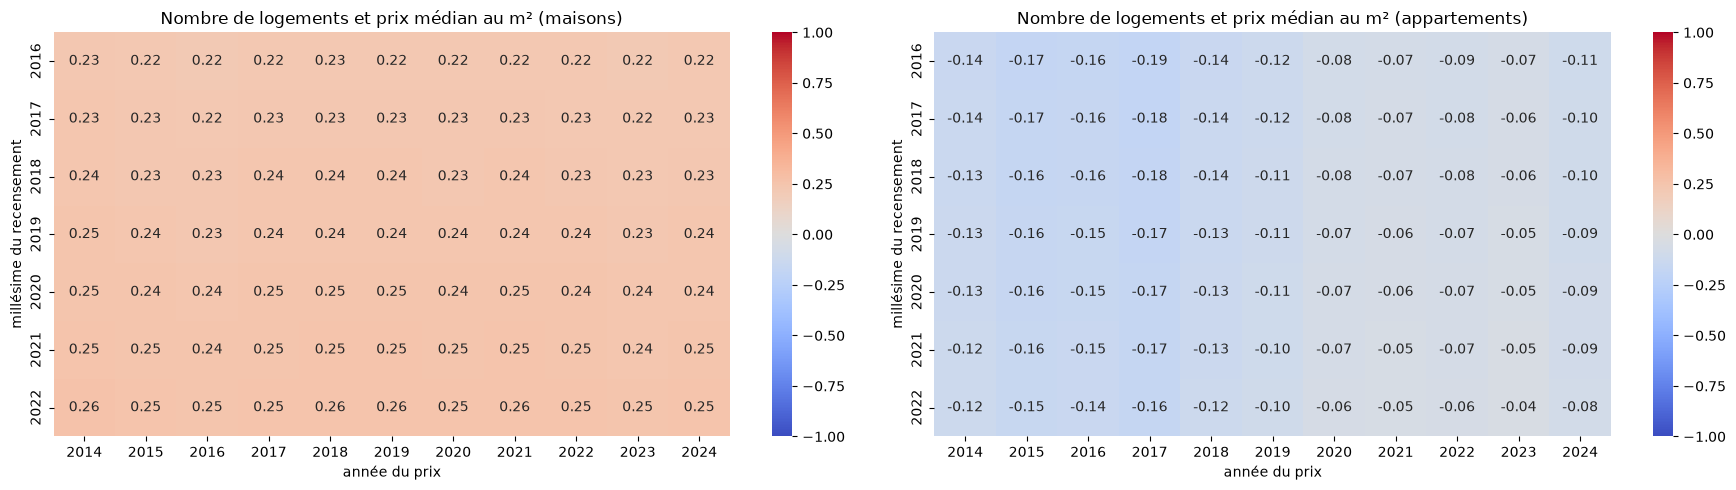

In [29]:
def matrice_rho(indicateur, type_bien):
    """rho de Spearman entre l'indicateur d'un millésime (lignes) et le prix d'une année (colonnes), par bassin."""
    ind = log_bv.pivot(index="BV2022", columns="millesime", values=indicateur)
    prix = prix_bv[type_bien]
    m = pd.DataFrame(index=ind.columns, columns=prix.columns, dtype=float)
    for mil in ind.columns:
        for an in prix.columns:
            d = pd.concat([ind[mil], prix[an]], axis=1).dropna()
            m.loc[mil, an] = stats.spearmanr(d.iloc[:, 0], d.iloc[:, 1])[0]
    m.index.name, m.columns.name = "millésime du recensement", "année du prix"
    return m

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, t in zip(axes, ["maisons", "appartements"]):
    sns.heatmap(matrice_rho("nb_logements", t), annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, center=0, ax=ax)
    ax.set_title(f"Nombre de logements et prix médian au m² ({t})")
plt.tight_layout()
plt.show()

**Comment lire le graphique :** chaque case donne le rho entre le nombre de logements d'un millésime (ligne) et le prix médian au m² d'une année (colonne). Une ligne lue de gauche à droite montre comment le lien d'un même recensement évolue avec l'année du prix ; une colonne lue de haut en bas montre si le choix du millésime change le lien avec le prix d'une même année.

**Constat :**
- **Le millésime ne change presque rien** : pour une même année de prix, le rho varie au plus de 0,03 entre les recensements 2016 et 2022.
- **Maisons : lien faible et positif** (rho de 0,22 à 0,26), stable sur toutes les années de prix.
- **Appartements : lien très faible et négatif** (rho de −0,19 à −0,04), qui varie un peu selon l'année du prix.

**Interprétation :**
- Les bassins gardent le même classement d'un recensement à l'autre : le nombre de logements décrit **où** l'on est, pas **quand**. Un recensement ancien donne la même information qu'un recensement récent.
- Les variations entre colonnes (appartements) viennent du prix et non du recensement : évolution du marché, et bassins qui dépassent le seuil de 20 ventes différents selon l'année (hypothèse).

**Impact projet :** le décalage d'environ trois ans imposé par la date de publication du recensement ne fait pas perdre d'information.

### Même calcul pour les 10 indicateurs
Pour chaque indicateur, la matrice millésime × année du prix est résumée par : le rho moyen, le rho minimum et maximum, et l'écart maximal entre millésimes pour une même année de prix (si cet écart est faible, le choix du millésime ne compte pas).

In [30]:
lignes = []
for ind in INDICATEURS_LOG:
    for t in ["maisons", "appartements"]:
        m = matrice_rho(ind, t)
        lignes.append({"indicateur": ind, "type de bien": t,
                       "rho moyen": round(m.stack().mean(), 2),
                       "rho min": round(m.stack().min(), 2),
                       "rho max": round(m.stack().max(), 2),
                       "écart max entre millésimes": round((m.max() - m.min()).max(), 2)})

display(pd.DataFrame(lignes).set_index(["indicateur", "type de bien"]))

rho moyen  rho min  rho max  \
indicateur         type de bien                                
nb_logements       maisons            0.24     0.22     0.26   
                   appartements      -0.11    -0.19    -0.04   
taux_vacance       maisons           -0.76    -0.78    -0.74   
                   appartements      -0.76    -0.79    -0.70   
part_rsec          maisons           -0.07    -0.09    -0.01   
                   appartements       0.29     0.23     0.33   
part_apparts       maisons            0.50     0.47     0.53   
                   appartements       0.29     0.25     0.34   
part_moins40m2     maisons            0.38     0.34     0.41   
                   appartements       0.35     0.33     0.39   
part_avant1946     maisons           -0.77    -0.79    -0.75   
                   appartements      -0.62    -0.65    -0.58   
anciennete_moyenne maisons           -0.75    -0.76    -0.74   
                   appartements      -0.49    -0.52    -0.46   
taille_menage      maisons            0.26     0.22     0.28   
                   appartements       0.07     0.01     0.12   
part_sans_voiture  maisons           -0.28    -0.34    -0.23   
                   appartements      -0.32    -0.34    -0.29   
part_parking       maisons            0.21     0.17     0.27   
                   appartements       0.34     0.31     0.38   

                                 écart max entre millésimes  
indicateur         type de bien                              
nb_logements       maisons                             0.03  
                   appartements                        0.02  
taux_vacance       maisons                             0.02  
                   appartements                        0.06  
part_rsec          maisons                             0.01  
                   appartements                        0.01  
part_apparts       maisons                             0.02  
                   appartements                        0.04  
part_moins40m2     maisons                             0.04  
                   appartements                        0.02  
part_avant1946     maisons                             0.01  
                   appartements                        0.02  
anciennete_moyenne maisons                             0.01  
                   appartements                        0.02  
taille_menage      maisons                             0.01  
                   appartements                        0.02  
part_sans_voiture  maisons                             0.05  
                   appartements                        0.03  
part_parking       maisons                             0.02  
                   appartements                        0.03

**Comment lire le tableau (exemple : taux de vacance, maisons) :**
- **rho moyen = −0,76** : en moyenne sur toutes les cases de la matrice (7 millésimes × 11 années de prix), les bassins où la vacance est la plus forte sont ceux où les maisons sont les moins chères. Repères : 0,1 lien faible, 0,3 moyen, 0,5 fort.
- **rho min = −0,78 et rho max = −0,74** : quel que soit le millésime et l'année du prix, le lien reste entre ces deux valeurs.
- **écart max entre millésimes = 0,02** : pour une même année de prix, changer de recensement (de 2016 à 2022) fait varier rho de 0,02 au plus. Le choix du millésime ne compte pas.

**Constat :**
- **Pour les 10 indicateurs, le millésime ne change presque rien** : écart maximal entre millésimes de 0,01 à 0,06.
- **Liens forts** : taux de vacance (−0,76 pour les maisons comme pour les appartements), part des logements construits avant 1946 (−0,77 et −0,62), ancienneté moyenne d'emménagement (−0,75 et −0,49), part des appartements pour les maisons (0,50).
- **Liens moyens** : part des logements de moins de 40 m² (0,38 et 0,35), part sans voiture (−0,28 et −0,32), part avec parking (0,21 et 0,34), part des appartements pour les appartements (0,29), part des résidences secondaires pour les appartements (0,29).
- **Liens faibles ou nuls** : nombre de logements (0,24 et −0,11), taille des ménages (0,26 et 0,07), résidences secondaires pour les maisons (−0,07).
- Au bassin de vie, les liens sont plus forts qu'à la commune (section 4.8 du rapport) : par exemple −0,76 contre −0,50 pour le taux de vacance des maisons.

**Interprétation :**
- Les indicateurs du parc de logements décrivent **où** l'on est : les bassins gardent le même classement d'un recensement à l'autre. Une seule photo suffit, et le décalage d'environ trois ans lié à la publication du recensement ne fait pas perdre d'information.
- Les liens les plus forts (vacance, logements anciens, ancienneté d'emménagement) opposent probablement les bassins ruraux en déprise aux bassins urbains (hypothèse) : comme pour les équipements, une partie de ces liens peut venir de la densité.
- Au bassin de vie, les effectifs sont plus grands qu'à la commune : les indicateurs sont moins bruités, d'où des liens plus forts (hypothèse).

**Biais / limites :** associations, pas causes ; seuil de 20 ventes, donc bassins différents selon l'année et le type de bien ; chaque millésime regroupe cinq années d'enquêtes, ce qui lisse les évolutions.

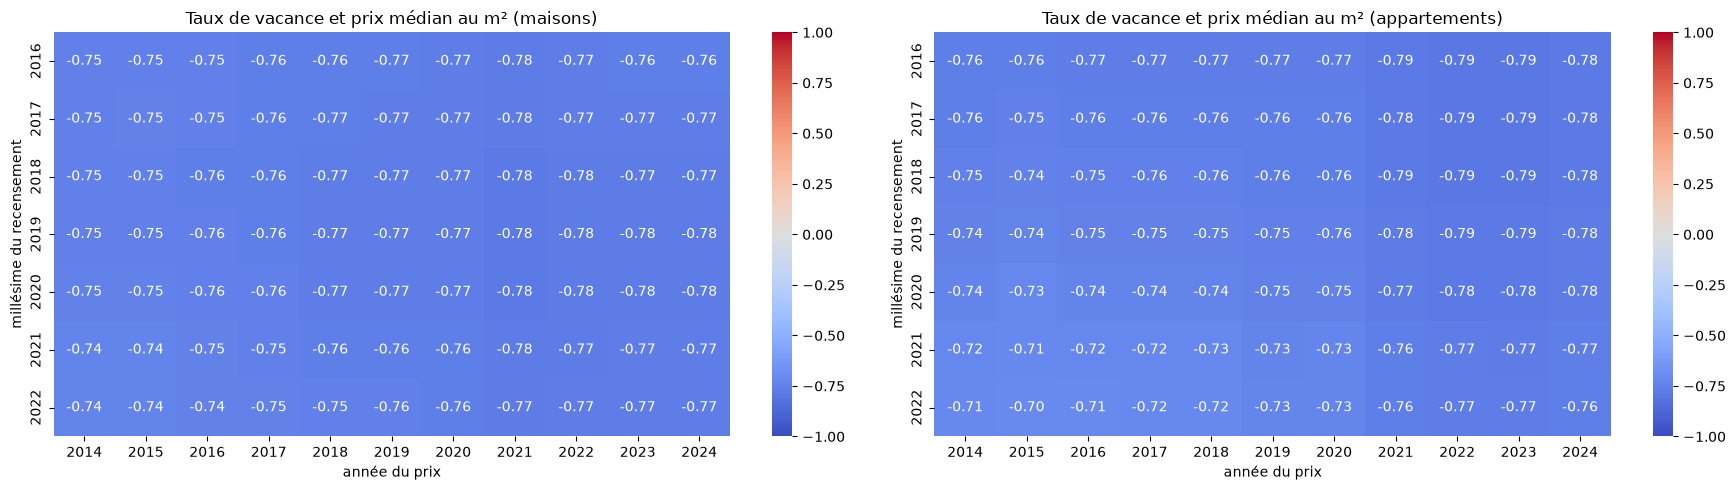

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, t in zip(axes, ["maisons", "appartements"]):
    sns.heatmap(matrice_rho("taux_vacance", t), annot=True, fmt=".2f", cmap="coolwarm",
                vmin=-1, vmax=1, center=0, ax=ax)
    ax.set_title(f"Taux de vacance et prix médian au m² ({t})")
plt.tight_layout()
plt.show()

**Constat :**
- **Lien fort et négatif** entre le taux de vacance et le prix au m² : rho de −0,74 à −0,78 pour les maisons, de −0,70 à −0,79 pour les appartements. Les bassins où beaucoup de logements sont vides sont les moins chers.
- **Le millésime ne change presque rien** : pour une même année de prix, le rho varie au plus de 0,03 (maisons) et 0,06 (appartements) entre les recensements 2016 et 2022.
- Pour les appartements, les recensements anciens sont un peu plus liés aux prix anciens (−0,76 entre le recensement 2016 et le prix 2014, −0,71 avec le recensement 2022) : l'écart reste faible face à la force du lien.

**Interprétation :** la vacance est une caractéristique durable du bassin, qui signale les territoires en déprise (hypothèse) : une seule photo suffit.

# Synthèse : parc de logements

| Constat majeur | Preuve | Conséquence projet | Action |
|---|---|---|---|
| Les millésimes 2016 à 2022 ont la même structure | Audit : environ 49 300 IRIS chaque année ; 21 des 26 effectifs de la préparation identiques | Les indicateurs sont comparables dans le temps | 10 des 12 indicateurs retenus en section 4.8 sont calculables de 2016 à 2022 |
| Deux indicateurs ne sont pas comparables | Période « depuis 2006 » qui s'allonge à chaque millésime ; suroccupation présente en 2022 seulement | Pas de suivi dans le temps possible | Gardés sur un seul millésime, comme les autres |
| Le millésime 2023 est une photo dans un nouveau format | Une seule année (`TIME_PERIOD` = 2023), format long, géographie 2025 | Pas de série d'évolution fournie par l'Insee | Non utilisé : il faudrait recoder chaque indicateur |
| Le choix du millésime ne change pas le lien avec le prix | Écart maximal entre millésimes de 0,01 à 0,06 pour les 10 indicateurs, maisons et appartements | Les indicateurs décrivent « où », pas « quand » | **Une photo suffit** : le recensement 2022 de la préparation est conservé ; un millésime plus ancien ou plus récent donnerait le même classement des bassins |

**Limite :** le millésime 2023 n'a pas été comparé aux autres ; la stabilité observée de 2016 à 2022 laisse penser qu'il donnerait les mêmes résultats (hypothèse). Le recensement 2022, publié en 2025, est postérieur aux ventes de 2014 à 2024 : cette anticipation est sans effet sur le classement des bassins, qui reste stable d'un millésime à l'autre.

### Audit de la BPE 2025 : structure du fichier

In [ ]:
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from config import DATA_RAW, DATA_OUT

bpe = pd.read_parquet(DATA_RAW / "BPE25.parquet")

print(bpe.shape)
print(bpe.dtypes)
display(bpe.head())

# Colonnes de texte : nombre de valeurs différentes et exemples (pour repérer la commune et le type d'équipement)
for col in bpe.columns:
    if bpe[col].dtype == object:
        print(col, ":", bpe[col].nunique(), "valeurs, ex.", bpe[col].dropna().unique()[:5].tolist())

### Audit de la BPE 2025 : colonnes, commune et type d'équipement

In [ ]:
# Liste complète des 95 colonnes
print(bpe.columns.tolist())

# Colonnes candidates pour la commune, le type et le domaine d'équipement
for col in ["DEPCOM", "DEP", "TYPEQU", "DOM", "SDOM", "BV2022"]:
    if col in bpe.columns:
        print(col, ":", bpe[col].nunique(), "valeurs, ex.", bpe[col].dropna().unique()[:8].tolist())

# Paris, Lyon, Marseille : arrondissements ou ville entière ?
if "DEPCOM" in bpe.columns:
    plm = bpe["DEPCOM"].str.match(r"^(751|6938|132)")
    print("Codes de Paris, Lyon, Marseille :", sorted(bpe.loc[plm, "DEPCOM"].unique())[:10])
    print("Villes entières présentes :", bpe["DEPCOM"].isin(["75056", "69123", "13055"]).sum(), "lignes")

### Quels types d'équipement compter ? Comparaison avec la BPE en évolution

In [ ]:
DOMAINES = {"A": "services", "B": "commerces", "D": "sante",
            "E": "transports", "F": "sports", "G": "tourisme"}   # C (enseignement) exclu

# BPE 2025 : métropole, 6 domaines
bpe25 = bpe[~bpe["DEP"].str.startswith("97") & bpe["DOM"].isin(DOMAINES)]

# BPE en évolution, 2025, au bassin de vie, métropole
evo = pd.read_csv(DATA_RAW / "DS_BPE_EVOLUTION_2025_data.csv", sep=None, engine="python", dtype=str)
evo = evo[(evo["GEO_OBJECT"] == "BV2022") & (evo["TIME_PERIOD"] == "2025")
          & ~evo["GEO"].str.startswith("97") & evo["FACILITY_TYPE"].str[0].isin(DOMAINES)].copy()
evo["OBS_VALUE"] = pd.to_numeric(evo["OBS_VALUE"])

# Types communs aux deux fichiers
types25, types_evo = set(bpe25["TYPEQU"]), set(evo["FACILITY_TYPE"])
print("Types BPE 2025 :", len(types25), "| BPE en évolution :", len(types_evo),
      "| communs :", len(types25 & types_evo))
print("Types seulement dans la BPE 2025 :", sorted(types25 - types_evo))
print("Équipements de ces types :", bpe25["TYPEQU"].isin(types25 - types_evo).sum(), "sur", len(bpe25))

# Concordance au bassin de vie : nombre d'équipements par bassin dans les deux fichiers
total_evo = evo.groupby("GEO")["OBS_VALUE"].sum()
for nom, b in [("option 1 (tous les types)", bpe25),
               ("option 2 (types communs)", bpe25[bpe25["TYPEQU"].isin(types_evo)])]:
    total25 = b.groupby("BV2022").size()
    ecart = (total25 / total_evo).dropna()
    print(nom, ": rapport BPE 2025 / évolution par bassin, médiane =", round(ecart.median(), 3),
          "| bassins à moins de 1 % d'écart :", round(((ecart - 1).abs() < 0.01).mean() * 100, 1), "%")

**Constat :** la BPE 2025 compte 209 types d'équipement dans les 6 domaines retenus, la BPE en évolution 149, dont 147 en commun. Les 62 types propres à la BPE 2025 représentent 14 % des équipements (385 808 sur 2 752 078). Avec tous les types, le nombre d'équipements par bassin dépasse de 17 % celui de la BPE en évolution (médiane du rapport : 1,174) et aucun bassin n'est à moins de 1 % d'écart. Avec les seuls types communs, la médiane du rapport est de 0,998 et 97,4 % des bassins sont à moins de 1 % d'écart.

**Décision :** on ne compte que les types communs aux deux fichiers. Les nombres d'équipements restent comparables à ceux de l'EDA complémentaire, dont les constats (liens avec le prix, stabilité entre millésimes) restent valables.